# MISHM: monitoreo de una red de puentes comparándolos entre sí con datos de vehículos

**Referencia:** Zeng, J., Mei, Q. y Gül, M. (2025). *Multibridge Inference Structural Health Monitoring (MISHM): A Drive-By Crowdsensing Approach at the Network Level*. Structural Control and Health Monitoring, 2025, 8624965. https://doi.org/10.1155/stc/8624965

**PDF:** [2025-zeng-mishm-multibridge-drive-by-shm.pdf](2025-zeng-mishm-multibridge-drive-by-shm.pdf)

**El artículo en una frase:** en lugar de comparar cada puente solo con su propia historia, MISHM compara **todos los puentes de una red entre sí** con las aceleraciones que registran los vehículos que pasan por ellos, y señala como dañado al puente cuyas comparaciones con los demás cambian más.

> **Sobre los ejemplos de código.** Los ejemplos reproducen el método con una **simulación propia simplificada** (modelo modal de vehículo y puente, sin tráfico de fondo). Sirven para entender cada paso; sus números no son los del artículo. Los valores **reportados por el artículo** se indican siempre de forma explícita.

<a id="indice"></a>
## Índice

- [Glosario](#glosario)
1. [Problema](#problema)
2. [Propósito](#proposito)
3. [Conceptos clave](#conceptos)
    - 3.1 [Monitoreo indirecto (drive-by) y crowdsensing](#c-driveby)
    - 3.2 [MFCC (coeficientes cepstrales en frecuencia Mel)](#c-mfcc)
    - 3.3 [Divergencia de Kullback–Leibler](#c-kl)
4. [Metodología](#metodologia)
    - 4.1 [Cálculo de los MFCC](#mfcc)
    - 4.2 [Divergencia KL entre dos puentes](#kl)
    - 4.3 [Factor de divergencia](#df)
    - 4.4 [PDM, factor de separación e índice de daño relativo (RDI)](#rdi)
    - 4.5 [Umbral de detección](#umbral)
5. [Procedimiento](#procedimiento)
    - 5.1 [Red de 12 puentes](#red)
    - 5.2 [Modelo de elementos finitos y escenarios de daño](#fe)
    - 5.3 [Vehículos aleatorios](#vehiculos)
    - 5.4 [Interacción vehículo–puente (VBI)](#vbi)
    - 5.5 [Generación de señales y MFCC](#senales)
    - 5.6 [Validación cruzada y prueba](#cv)
6. [Resultados](#resultados)
    - 6.1 [Matrices de diferencia porcentual (PDM)](#res-pdm)
    - 6.2 [Distribución de las diferencias del puente 5](#res-box)
    - 6.3 [RDI frente al umbral](#res-rdi)
    - 6.4 [Influencia del número de vehículos](#res-n)
    - 6.5 [Daños pequeños](#res-small)
7. [Conclusiones y limitaciones](#conclusiones)

<a id="glosario"></a>
## Glosario

Términos y siglas que aparecen en este notebook, agrupados por tema. Los marcados con → tienen una ficha completa en [Conceptos clave](#conceptos).

**Monitoreo de puentes**

- **SHM** (*Structural Health Monitoring*, monitoreo de la salud estructural): seguimiento del estado de una estructura con mediciones periódicas o continuas, para detectar daño a tiempo.
- **Monitoreo directo:** los sensores se instalan sobre la estructura (acelerómetros, galgas).
- **Monitoreo indirecto o *drive-by*** → [3.1](#c-driveby): los sensores van en un vehículo que cruza el puente.
- ***Crowdsensing*** → [3.1](#c-driveby): recolección de datos con los dispositivos de mucha gente, p. ej. los teléfonos dentro de autos comunes.
- **Ciudad inteligente** (*smart city*): ciudad que usa sensores y datos para gestionar su infraestructura.
- **Línea base** (*baseline*): datos del estado sano que sirven de referencia para detectar cambios.
- **Estado desconocido o de monitoreo:** datos nuevos cuya condición (sano o dañado) se quiere determinar.
- **Falso positivo o falsa alarma:** declarar dañado un puente sano. **Falso negativo:** no detectar un puente dañado.
- **MISHM** (*Multibridge Inference SHM*): el marco que propone el artículo; infiere la salud de cada puente comparándolo con los demás de la red.

**Dinámica estructural**

- **Frecuencia natural** ($f_n$): frecuencia a la que la estructura vibra libremente en su modo $n$. Depende de la rigidez y la masa; si el daño reduce la rigidez, la frecuencia baja.
- **Forma modal:** forma con la que se deforma la estructura cuando vibra en un modo.
- **Curvatura modal:** segunda derivada de la forma modal; indica dónde se flexiona más la estructura en ese modo.
- **Rigidez a flexión** ($EI$): producto del módulo de elasticidad $E$ por la inercia $I$; mide cuánto se resiste la viga a flexionarse.
- **Amortiguamiento** ($\zeta$): disipación de energía que hace que la vibración se apague.
- **Viga de Euler–Bernoulli:** modelo de viga esbelta que desprecia la deformación por cortante.
- **Viga simplemente apoyada:** apoyos que impiden el desplazamiento vertical pero permiten el giro.
- **Elementos finitos (FE):** método numérico que divide la estructura en elementos pequeños para calcular su respuesta.
- **Superposición modal:** escribir la respuesta como suma de las contribuciones de unos pocos modos.
- **VBI** (*Vehicle–Bridge Interaction*, interacción vehículo–puente): acoplamiento dinámico en el que el vehículo excita al puente y el puente al vehículo.
- **Cuarto de carro** (*quarter car*): modelo simple de vehículo, una masa sobre un resorte y un amortiguador.
- **Rugosidad del pavimento:** irregularidades de la superficie que también hacen vibrar al vehículo.
- **OpenSees:** programa libre de análisis estructural por elementos finitos; lo usan los autores.
- **Runge–Kutta (RK4):** método numérico para integrar ecuaciones diferenciales paso a paso en el tiempo.

**Procesamiento de señales**

- **Espectro y transformada de Fourier (FFT):** el espectro muestra cuánta amplitud tiene una señal en cada frecuencia; la FFT (*Fast Fourier Transform*) es el algoritmo rápido para calcularlo.
- **PSD** (*Power Spectral Density*, densidad espectral de potencia): cómo se reparte la potencia de una señal entre las frecuencias. Aquí se usa para generar la rugosidad.
- **Frecuencia de muestreo:** muestras por segundo (100 Hz en el artículo).
- **Límite de Nyquist:** la frecuencia máxima que se puede representar es la mitad de la de muestreo (50 Hz aquí).
- **Resolución espectral:** separación mínima entre dos frecuencias que se pueden distinguir; es aproximadamente 1/(duración de la señal).
- **Filtro gaussiano:** suavizado que promedia cada muestra con sus vecinas con pesos en forma de campana; quita ruido de alta frecuencia.
- **Escala Mel:** escala de frecuencias no lineal, más fina en frecuencias bajas que en altas.
- **Banco de filtros:** conjunto de filtros (aquí triangulares) que dividen el espectro en bandas.
- **DCT** (*Discrete Cosine Transform*, transformada discreta del coseno): expresa una secuencia como suma de cosenos y concentra la información en los primeros coeficientes.
- **Cepstrum:** "espectro del logaritmo del espectro"; separa la forma general del espectro de sus detalles.
- **Envolvente espectral:** forma suave y general del espectro, sin los picos finos.
- **MFCC** (*Mel-Frequency Cepstral Coefficients*) → [3.2](#c-mfcc): resumen compacto de la envolvente espectral de una señal.
- **Ruido de 10 %:** perturbación aleatoria sumada a la señal, con desviación estándar igual al 10 % de la de la señal.

**Estadística**

- **Distribución normal multivariada:** generalización de la campana de Gauss a vectores; queda definida por un vector de medias y una matriz de covarianza.
- **Vector de medias** ($\boldsymbol{\mu}$): promedio de cada componente del vector.
- **Matriz de covarianza** ($\boldsymbol{\Sigma}$): varianzas en la diagonal y covarianzas fuera de ella; describe la dispersión de los datos y cómo se relacionan sus componentes.
- **Traza** ($\operatorname{tr}$): suma de los elementos de la diagonal de una matriz.
- **Determinante** ($\det$): número que mide el "volumen" de la dispersión descrita por una matriz de covarianza.
- **Distancia de Mahalanobis:** distancia entre un punto y una distribución, medida en unidades de la dispersión de los datos.
- **Divergencia de Kullback–Leibler (KL)** → [3.3](#c-kl): medida de cuánto se diferencia una distribución de probabilidad de otra.
- **Normal truncada:** distribución normal recortada a un rango [mín, máx].
- **Validación cruzada:** dividir los datos en partes, una para ajustar y otra para validar, y repetir con divisiones distintas.
- **Coeficiente de variación (CV):** desviación estándar dividida por la media; mide la dispersión relativa.
- **Diagrama de caja** (*boxplot*): la línea es la mediana, la caja abarca el 50 % central de los datos (rango intercuartílico) y los bigotes muestran la extensión del resto.
- **Curva ROC:** gráfica de la tasa de detección frente a la tasa de falsas alarmas para distintos umbrales.

**Índices propios del artículo**

- **DF** (*Divergence Factor*, factor de divergencia): divergencia KL entre dos puentes transformada con un logaritmo, Ec. (7).
- **PDM** (*Percentage Difference Matrix*, matriz de diferencia porcentual): cambio porcentual de cada DF respecto a la línea base, Ec. (8).
- **SF** (*Separation Factor*, factor de separación): parte del cambio total de la red que corresponde a un puente, Ec. (9).
- **RDI** (*Relative Damage Index*, índice de daño relativo): $e^{SF} - 1$, Ec. (10).
- **Umbral:** media más 2.5 desviaciones estándar del RDI en estado sano, Ec. (11).

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display, Markdown
from scipy.linalg import eigh
from scipy.ndimage import gaussian_filter1d
from scipy.stats import truncnorm, norm

SEED = 42
rng = np.random.default_rng(SEED)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})


# Display a table with its caption above it
def show_table(df, number, caption, precision=2, hide_index=False):
    display(Markdown(f"**Tabla {number}.** {caption}"))
    styled = df.style.format(precision=precision)
    display(styled.hide(axis="index") if hide_index else styled)


# Display a figure with its caption below it
def show_figure(fig, number, caption):
    display(fig)
    plt.close(fig)
    display(Markdown(f"**Figura {number}.** {caption}"))

<a id="problema"></a>
## 1. Problema

- **Puentes envejecidos.** En EE. UU., el 42 % de más de 617 000 puentes tiene al menos 50 años y el 7.5 % es estructuralmente deficiente (ASCE, 2021).
- **El SHM tradicional no escala.** Usa sensores fijos instalados en cada puente: es caro, exige acceso a la estructura y vigila **un puente a la vez**. Para una red urbana con cientos de puentes no es viable.
- **Drive-by y crowdsensing.** El vehículo que cruza el puente actúa como sensor (Yang et al., 2004). Si se usan los teléfonos de muchos vehículos (*crowdsensing*), el monitoreo es barato y cubre mucho territorio.
- **Vacío que ataca el artículo.** Los métodos drive-by y de crowdsensing anteriores (p. ej., Mei y Gül, 2019, con MFCC y divergencia KL; Shirzad-Ghaleroudkhani y Gül, 2024) evalúan **cada puente por separado** frente a su propia línea base. No aprovechan que en una ciudad se miden muchos puentes al mismo tiempo y con el mismo tipo de tráfico.

**Tabla 1.** Enfoques de monitoreo y qué compara cada uno.

| Enfoque | Sensores | Escala | Con qué se compara un puente |
|---|---|---|---|
| SHM tradicional | Fijos en el puente | Un puente | Su propia línea base |
| Drive-by (un vehículo instrumentado) | En el vehículo | Pocos puentes | Su propia línea base |
| Crowdsensing (muchos vehículos) | Teléfonos o sensores de vehículos | Muchos puentes | Su propia línea base |
| **MISHM (este artículo)** | Teléfonos o sensores de vehículos | Red de puentes | **Todos los demás puentes de la red** |

<a id="proposito"></a>
## 2. Propósito

**Objetivo:** desarrollar un marco de SHM escalable que detecte daño en una **red** de puentes usando solo aceleraciones medidas en vehículos que circulan.

**Idea central ("inferencia multipuente"):** la salud de cada puente se juzga comparando sus características dinámicas con las de **todos** los demás puentes. Si un puente se daña, cambian sus comparaciones con todos los demás; si no se daña, sus comparaciones se mantienen.

**Aportes:**

1. **Matriz de factores de divergencia** $m \times m$: mide qué tan distinta es la respuesta de cada par de puentes.
2. **Índice de daño relativo (RDI):** resume cuánto cambió cada puente respecto al resto de la red.
3. **Umbral por puente** obtenido por validación cruzada con los datos sanos.

**Hipótesis de los autores:** la redundancia de comparaciones múltiples reduce los daños no detectados (falsos negativos), y la robustez crece con el número de puentes y de vehículos. Se valida **solo con simulaciones numéricas**.

<a id="conceptos"></a>
## 3. Conceptos clave

El artículo se apoya en tres ideas. Aquí se explica qué es cada una, para qué sirve, por qué se eligió y cuándo conviene o no usarla. Cómo las aplica el artículo (fórmulas y código) está en la [Metodología](#metodologia).

<a id="c-driveby"></a>
### 3.1 Monitoreo indirecto (*drive-by*) y *crowdsensing*

**Qué es.**

- **Monitoreo indirecto o *drive-by*:** medir la vibración de un puente con sensores colocados en un **vehículo que lo cruza**, en lugar de instalarlos en el puente. Mientras cruza, el vehículo vibra con sus propias frecuencias y también con las del puente, así que el puente queda "grabado" en la aceleración del vehículo. La idea se demostró por primera vez en Yang et al. (2004).
- ***Crowdsensing*** (de *crowd*, multitud, y *sensing*, medición): usar como sensores los dispositivos de **mucha gente**, por ejemplo los teléfonos de conductores comunes, en lugar de un vehículo de ensayo.

**Para qué sirve.** Para identificar propiedades del puente (frecuencias, formas modales, cambios por daño) sin instalar nada en él y sin cerrar el tráfico.

**Por qué se usó en este artículo.** Es la única forma barata de medir **muchos puentes a la vez**: el tráfico diario cruza todos los puentes de la red y genera datos sin costo de instalación. Sin crowdsensing no habría datos de toda la red que comparar.

**Cuándo conviene usarlo.**

- Redes con muchos puentes cortos o medianos, cuyas frecuencias principales están por debajo de ~20 Hz.
- Puentes con mucho tráfico, que dan cientos o miles de cruces.
- Cuando el objetivo es una **alerta temprana** (¿cambió algo?) más que una medición precisa.

**Cuándo no conviene.**

- Puentes críticos que requieren monitoreo continuo y preciso: los sensores fijos dan señales más largas y limpias.
- Puentes con poco tráfico: no hay suficientes cruces para que la estadística funcione.
- Cuando la respuesta del vehículo tapa la del puente: si la frecuencia del vehículo es parecida a la del puente, o si la rugosidad del pavimento es alta (ver Figura 9).
- Cuando se necesita alta resolución en frecuencia: cada cruce dura solo unos segundos.

**Alternativas.** Monitoreo directo con sensores fijos; vehículo de ensayo instrumentado (drive-by sin crowdsensing); inspección visual.

<a id="c-mfcc"></a>
### 3.2 MFCC (coeficientes cepstrales en frecuencia Mel)

**Qué es.** MFCC son las siglas de *Mel-Frequency Cepstral Coefficients*. Es una forma de describir con unos pocos números la **envolvente del espectro** de una señal, es decir, su forma general: dónde está la energía y cómo se reparte, sin los detalles finos. Se crearon para el reconocimiento de voz (Davis y Mermelstein, 1980): dos personas que dicen la misma vocal producen espectros con la misma forma general, y los MFCC capturan esa forma.

Qué significa cada parte del nombre:

- ***Mel:*** las frecuencias se miden en la escala Mel, que da más resolución a las frecuencias bajas que a las altas.
- ***Frequency:*** se trabaja con el espectro de la señal, no con la señal en el tiempo.
- ***Cepstral:*** viene de *cepstrum*, anagrama de *spectrum*. Es el "espectro del logaritmo del espectro": al transformar otra vez el log-espectro se separan sus variaciones lentas (forma general) de las rápidas (detalles).
- ***Coefficients:*** el resultado es un vector de números, del que se conservan solo los primeros $s$.

En resumen: **espectro → escala Mel → logaritmo → DCT → primeros $s$ coeficientes = resumen compacto de la forma del espectro**.

**Para qué sirve.** Para convertir cada señal, sea de la duración que sea, en un vector corto de números comparables entre sí. Esos vectores alimentan estadísticas o modelos de aprendizaje automático.

**Por qué se usó en este artículo.**

- Cada cruce dura 2–3 s, así que la resolución espectral es de 0.3–0.5 Hz, mientras que el daño baja $f_1$ solo 0.04–0.1 Hz (Tabla 6). Con señales así no se pueden medir picos de frecuencia con precisión, pero sí detectar cambios sutiles en la **forma** del espectro.
- La escala Mel adaptada da más resolución y más peso a las frecuencias bajas, donde están los modos principales de estos puentes.
- El grupo de los autores ya lo había validado en laboratorio y en campo (Mei y Gül, 2019; Shirzad-Ghaleroudkhani y Gül, 2024).

**Cuándo conviene usarlo.**

- Muchas señales cortas y ruidosas.
- Cuando interesa **detectar cambios** (anomalías) más que medir parámetros físicos.
- Como entrada compacta para estadística (KL, PCA) o aprendizaje automático.

**Cuándo no conviene.**

- Cuando se necesitan parámetros físicos (frecuencias, formas modales, amortiguamiento): los MFCC no tienen interpretación física directa.
- Cuando la información está en frecuencias altas, porque la escala Mel las comprime.
- Cuando otros factores cambian el espectro tanto como el daño (velocidad, tipo de vehículo, temperatura): los MFCC responden a todo cambio del espectro, no solo al daño.

**Alternativas.** Picos del espectro (FFT o PSD); identificación modal (p. ej. SSI o FDD); transformadas tiempo–frecuencia como las wavelets o la transformada sincrocomprimida (Matarazzo et al., 2018); PCA del espectro.

<a id="c-kl"></a>
### 3.3 Divergencia de Kullback–Leibler (KL)

**Qué es.** Una medida de **cuánto se diferencia una distribución de probabilidad $P$ de otra $Q$**. Viene de la teoría de la información (Kullback y Leibler, 1951): es la información que se pierde si se usa $Q$ para aproximar $P$. Su definición general es $D_{KL}(P \Vert Q) = \int p(x) \ln \frac{p(x)}{q(x)}\,dx$, donde $p$ y $q$ son las densidades de probabilidad.

- Siempre es $\ge 0$, y vale $0$ solo si las dos distribuciones son iguales.
- **No es simétrica:** $D_{KL}(P \Vert Q) \neq D_{KL}(Q \Vert P)$. Por eso se llama "divergencia" y no "distancia".

**Para qué sirve.** Para comparar dos conjuntos de datos **completos** (centro, dispersión y forma), no solo sus promedios.

**Por qué se usó en este artículo.**

- Cada puente queda descrito por una **nube** de vectores MFCC, uno por vehículo. El daño puede mover el centro de la nube y también cambiar su dispersión; la KL capta ambas cosas.
- Si se supone que la nube es normal multivariada, la KL tiene una fórmula cerrada (Ec. 6) que solo usa medias y covarianzas, y se calcula muy rápido para los 132 pares de puentes.
- El grupo de los autores ya la había usado con MFCC para un solo puente (Mei y Gül, 2019).

**Cuándo conviene usarla.**

- Cuando hay muchas muestras por grupo: para estimar bien $\boldsymbol{\Sigma}$ se necesitan muchos más vehículos que coeficientes ($p \gg s$).
- Cuando los datos son aproximadamente normales.
- Para comparar un estado de referencia con un estado nuevo.

**Cuándo no conviene.**

- Con pocas muestras o muchas dimensiones: la covarianza queda mal estimada o no se puede invertir.
- Con distribuciones muy alejadas de la normal (asimétricas o con varios grupos): la fórmula cerrada deja de ser válida.
- Cuando se necesita una medida simétrica o una distancia en sentido estricto.

**Alternativas.** Distancia de Mahalanobis (solo compara medias); divergencia de Jensen–Shannon (versión simétrica de la KL); distancia de Bhattacharyya; distancia de Wasserstein; prueba $T^2$ de Hotelling.

<a id="metodologia"></a>
## 4. Metodología

El método (Fig. 2 del artículo) tiene dos etapas:

1. **A bordo de cada vehículo:** la aceleración vertical registrada al cruzar el puente se convierte en un vector de $s$ coeficientes MFCC. Los vectores de los $p_i$ vehículos que cruzaron el puente $i$ forman su matriz $\mathbf{M}_i$.
2. **Análisis estadístico de la red:** se compara cada par de puentes con la divergencia KL, se arma la matriz de factores de divergencia y se mide cuánto cambió respecto a la línea base. De ahí salen el RDI de cada puente y la decisión (dañado o no).

La Figura 1 resume el flujo completo y la Tabla 2 reúne la notación.

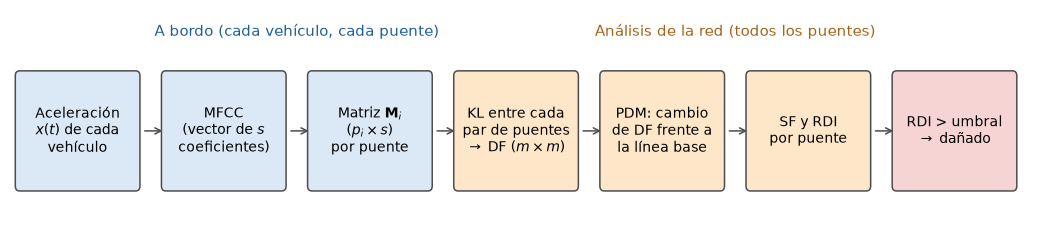

**Figura 1.** Flujo del método MISHM (esquema propio basado en las Figs. 1 y 2 del artículo). Azul: procesamiento de cada señal; naranja: comparación entre puentes; rojo: decisión.

In [2]:
# Flowchart of the MISHM framework (own schematic)
steps = [
    ("Aceleración\n$x(t)$ de cada\nvehículo", "#dbe9f6"),
    ("MFCC\n(vector de $s$\ncoeficientes)", "#dbe9f6"),
    ("Matriz $\\mathbf{M}_i$\n($p_i \\times s$)\npor puente", "#dbe9f6"),
    ("KL entre cada\npar de puentes\n$\\rightarrow$ DF ($m \\times m$)", "#fde7c8"),
    ("PDM: cambio\nde DF frente a\nla línea base", "#fde7c8"),
    ("SF y RDI\npor puente", "#fde7c8"),
    ("RDI > umbral\n$\\rightarrow$ dañado", "#f7d4d4"),
]
fig, ax = plt.subplots(figsize=(12, 2.6))
ax.set_xlim(0, len(steps) * 1.7)
ax.set_ylim(0, 2.2)
ax.axis("off")
for k, (label, color) in enumerate(steps):
    x0 = 0.1 + k * 1.7
    ax.add_patch(FancyBboxPatch((x0, 0.45), 1.35, 1.1, boxstyle="round,pad=0.05",
                                fc=color, ec="0.3"))
    ax.text(x0 + 0.675, 1.0, label, ha="center", va="center", fontsize=9)
    if k < len(steps) - 1:
        ax.annotate("", xy=(x0 + 1.7, 1.0), xytext=(x0 + 1.42, 1.0),
                    arrowprops=dict(arrowstyle="->", color="0.3"))
ax.text(0.1 + 1.5 * 1.7 + 0.675, 1.95, "A bordo (cada vehículo, cada puente)", ha="center", fontsize=10, color="#1f5f99")
ax.text(0.1 + 4.5 * 1.7 + 0.675, 1.95, "Análisis de la red (todos los puentes)", ha="center", fontsize=10, color="#a5641a")
show_figure(fig, 1, "Flujo del método MISHM (esquema propio basado en las Figs. 1 y 2 del artículo). "
                    "Azul: procesamiento de cada señal; naranja: comparación entre puentes; rojo: decisión.")

**Tabla 2.** Notación principal.

| Símbolo | Significado |
|---|---|
| $m$ | Número de puentes de la red (12 en el artículo) |
| $p_i$ | Número de vehículos que cruzan el puente $i$ (1000 en el artículo) |
| $s$ | Número de coeficientes MFCC que se conservan por señal |
| $\mathbf{M}_i$ | Matriz MFCC del puente $i$: una fila por vehículo, una columna por coeficiente |
| $\boldsymbol{\mu}_i,\ \boldsymbol{\Sigma}_i$ | Vector de medias y matriz de covarianza de las filas de $\mathbf{M}_i$ |
| $D_{KL}(\mathbf{M}_i \Vert \mathbf{M}_j)$ | Divergencia KL del puente $i$ respecto al puente $j$ |
| $DF[i,j]$ | Factor de divergencia entre los puentes $i$ y $j$ |
| $\Delta DF[i,j]$ | Diferencia porcentual de $DF[i,j]$ entre el estado desconocido y la línea base (PDM) |
| $SF_i$, $RDI_i$ | Factor de separación e índice de daño relativo del puente $i$ |

<a id="mfcc"></a>
### 4.1 Cálculo de los MFCC

Qué son los MFCC y por qué se eligieron está en la [ficha 3.2](#c-mfcc). Aquí se sigue el cálculo paso a paso. La idea: si el puente se daña, sus frecuencias bajan, el espectro cambia de forma y cambian los MFCC.

**Pasos** (Fig. 3 del artículo): filtro gaussiano → transformada de Fourier y remuestreo a 0–20 Hz → banco de filtros Mel → logaritmo de las energías → transformada discreta del coseno (DCT).

**Por qué el logaritmo y la DCT.**

- **Logaritmo:** comprime el rango, para que un pico grande no tape a los pequeños. Además convierte productos en sumas. La aceleración del vehículo es la vibración del puente "filtrada" por la suspensión, lo que en frecuencia es un producto, $X = H_{\text{veh}} \cdot X_{\text{puente}}$. En escala logarítmica queda $\log X = \log H_{\text{veh}} + \log X_{\text{puente}}$, donde $X$ es el espectro medido en el vehículo, $X_{\text{puente}}$ el de la vibración del puente bajo la rueda y $H_{\text{veh}}$ la función de transferencia de la suspensión. Los aportes del vehículo y del puente se suman.
- **DCT:** las energías de filtros vecinos están muy correlacionadas. La DCT las convierte en coeficientes casi independientes, ordenados de lo general (primeros coeficientes) a lo fino (últimos). Esto facilita compararlos estadísticamente con medias y covarianzas, como se hace en la sección 4.2.

**Paso 1. Escala Mel adaptada a puentes.** La escala Mel nació para imitar el oído humano: es más fina en frecuencias bajas que en altas. En audio se usa $m = 1127\,\ln(1 + f/700)$. El artículo cambia 700 Hz por **5 Hz**, para que la resolución fina caiga donde están las frecuencias de los puentes:

$$m = 5\,\ln\!\left(1 + \frac{f}{5}\right) \qquad\Longleftrightarrow\qquad f = 5\left(e^{m/5} - 1\right) \tag{1}$$

donde $f$ es la frecuencia en Hz y $m$ la frecuencia en la escala Mel (Ecs. 1, 2 y 5 del artículo). Se eligen $N$ frecuencias clave **igualmente espaciadas en Mel** entre $f_{\text{first}} = 0$ y $f_{\text{last}} = 20$ Hz:

$$\Delta m = \frac{m_{\text{last}} - m_{\text{first}}}{N - 1}, \qquad m_i = m_{\text{first}} + (i - 1)\,\Delta m, \quad i = 1, \dots, N \tag{2}$$

(Ecs. 3 y 4 del artículo). Al volver a Hz, quedan **apretadas en frecuencias bajas y separadas en las altas**.

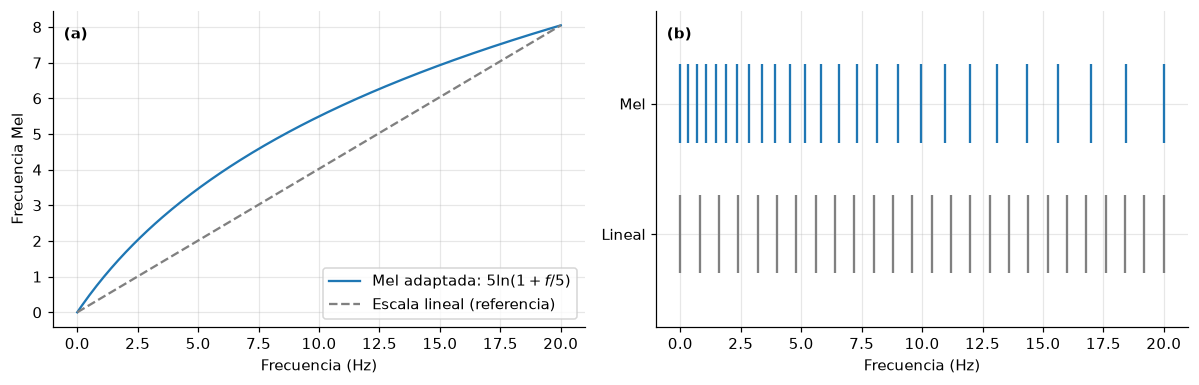

**Figura 2.** (a) Escala Mel adaptada del artículo frente a una escala lineal. (b) Las $N=26$ frecuencias clave: igualmente espaciadas en Mel, quedan más juntas en frecuencias bajas que en altas.

In [3]:
F_MAX = 20.0     # upper frequency of the analysis band (Hz)
N_KEY = 26       # number of key frequencies N (not reported in the paper)
N_GRID = 401     # points of the resampled spectrum between 0 and 20 Hz


def hz_to_mel(f):
    return 5.0 * np.log(1.0 + f / 5.0)


def mel_to_hz(m):
    return 5.0 * (np.exp(m / 5.0) - 1.0)


# Key frequencies: equally spaced in Mel, then mapped back to Hz
key_mel = np.linspace(hz_to_mel(0.0), hz_to_mel(F_MAX), N_KEY)
key_hz = mel_to_hz(key_mel)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
f = np.linspace(0, F_MAX, 200)
axes[0].plot(f, hz_to_mel(f), label="Mel adaptada: $5\\ln(1+f/5)$")
axes[0].plot(f, f * hz_to_mel(F_MAX) / F_MAX, "--", color="0.5", label="Escala lineal (referencia)")
axes[0].set_xlabel("Frecuencia (Hz)")
axes[0].set_ylabel("Frecuencia Mel")
axes[0].legend()
axes[0].text(0.02, 0.95, "(a)", transform=axes[0].transAxes, fontweight="bold", va="top")
axes[1].eventplot(key_hz, lineoffsets=1, linelengths=0.6, color="C0")
axes[1].eventplot(np.linspace(0, F_MAX, N_KEY), lineoffsets=0, linelengths=0.6, color="0.5")
axes[1].set_yticks([0, 1], ["Lineal", "Mel"])
axes[1].set_xlabel("Frecuencia (Hz)")
axes[1].text(0.02, 0.95, "(b)", transform=axes[1].transAxes, fontweight="bold", va="top")
fig.tight_layout()
show_figure(fig, 2, f"(a) Escala Mel adaptada del artículo frente a una escala lineal. "
                    f"(b) Las $N={N_KEY}$ frecuencias clave: igualmente espaciadas en Mel, quedan más juntas en frecuencias bajas que en altas.")

**Paso 2. Banco de filtros triangulares.** Cada frecuencia clave $f_i$ es el centro de un triángulo que va de la frecuencia clave anterior ($f_{\text{left}}$) a la siguiente ($f_{\text{right}}$). Con $N$ frecuencias clave hay $N-2$ filtros. El artículo usa triángulos **normalizados** (área igual a 1, Ec. 6 del artículo):

$$H_i(k) = \begin{cases} \dfrac{2\,(k - f_{\text{left}})}{(f_{\text{center}} - f_{\text{left}})(f_{\text{right}} - f_{\text{left}})}, & f_{\text{left}} \le k < f_{\text{center}} \\[2ex] \dfrac{2\,(f_{\text{right}} - k)}{(f_{\text{right}} - f_{\text{left}})(f_{\text{right}} - f_{\text{center}})}, & f_{\text{center}} \le k < f_{\text{right}} \\[2ex] 0, & \text{en otro caso} \end{cases} \tag{3}$$

donde $H_i(k)$ es el peso del filtro $i$ en la frecuencia $k$ (Hz) y $f_{\text{center}} = f_i$. Como el área es 1, los filtros anchos (altas frecuencias) son **más bajos**: el banco da más peso a las frecuencias bajas, donde están los modos principales de los puentes (Figura 3).

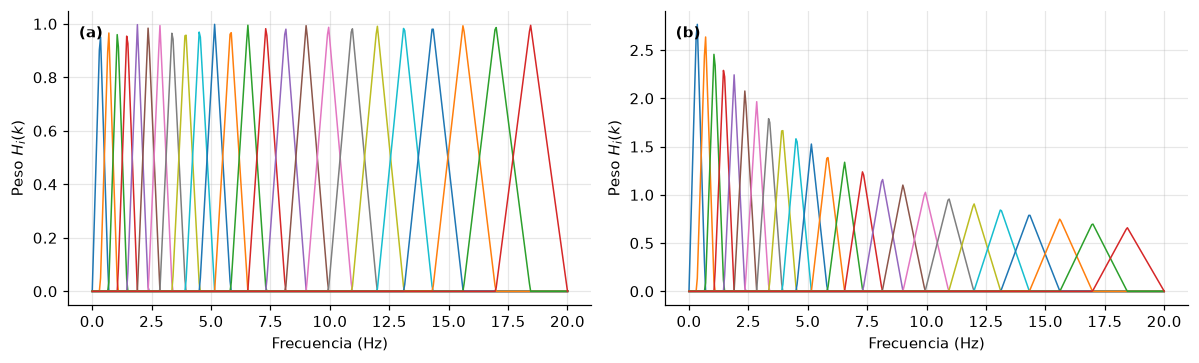

**Figura 3.** Banco de filtros Mel (equivalente a la Fig. 4 del artículo). (a) Triángulos sin normalizar (altura 1). (b) Triángulos normalizados (área 1), los que usa el artículo: los de baja frecuencia pesan mucho más.

In [4]:
f_grid = np.linspace(0.0, F_MAX, N_GRID)   # frequency bins k (Hz)


def mel_filter_bank(normalize=True):
    # One triangular filter per interior key frequency (N - 2 filters)
    H = np.zeros((N_KEY - 2, N_GRID))
    for i in range(1, N_KEY - 1):
        fl, fc, fr = key_hz[i - 1], key_hz[i], key_hz[i + 1]
        rise = (f_grid >= fl) & (f_grid < fc)
        fall = (f_grid >= fc) & (f_grid < fr)
        if normalize:   # unit-area triangles (paper, Eq. 6)
            H[i - 1, rise] = 2 * (f_grid[rise] - fl) / ((fc - fl) * (fr - fl))
            H[i - 1, fall] = 2 * (fr - f_grid[fall]) / ((fr - fl) * (fr - fc))
        else:           # unit-height triangles
            H[i - 1, rise] = (f_grid[rise] - fl) / (fc - fl)
            H[i - 1, fall] = (fr - f_grid[fall]) / (fr - fc)
    return H


H_mel = mel_filter_bank(normalize=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
for ax, H, tag in zip(axes, [mel_filter_bank(False), H_mel], ["(a)", "(b)"]):
    ax.plot(f_grid, H.T, lw=1)
    ax.set_xlabel("Frecuencia (Hz)")
    ax.set_ylabel("Peso $H_i(k)$")
    ax.text(0.02, 0.95, tag, transform=ax.transAxes, fontweight="bold", va="top")
fig.tight_layout()
show_figure(fig, 3, "Banco de filtros Mel (equivalente a la Fig. 4 del artículo). (a) Triángulos sin normalizar (altura 1). "
                    "(b) Triángulos normalizados (área 1), los que usa el artículo: los de baja frecuencia pesan mucho más.")

**Paso 3. Energías, logaritmo y DCT.** Cada filtro "recoge" la energía del espectro en su banda, y se toma el logaritmo (Ec. 7 del artículo):

$$\log(E_i) = \log\!\left(\sum_{k} H_i(k)\,\tilde{x}_f(f_k)\right) \tag{4}$$

donde $\tilde{x}_f(f_k)$ es la amplitud del espectro de la señal filtrada en el bin $f_k$ y $E_i$ la energía del filtro $i$. Por último, la DCT convierte las $N-2$ log-energías en coeficientes (Ec. 8 del artículo):

$$\text{MFCC}_j = \sum_{i=2}^{N-1} \log(E_i)\,\cos\!\left(\frac{\pi}{N-2}\,(i - 1.5)\,j\right), \qquad j = 2, \dots, N-1 \tag{5}$$

La DCT descompone la curva de log-energías en "ondas" de coseno: los primeros coeficientes describen la forma general del espectro y los últimos los detalles finos. Se conservan los primeros $s$.

Antes de la FFT, la señal pasa por un **filtro gaussiano** con $\sigma = 0.5$ muestras para quitar ruido de alta frecuencia. Como cada vehículo tarda un tiempo distinto en cruzar, el espectro se **remuestrea** a una malla fija de 0–20 Hz: así todos los vectores MFCC son comparables.

La Figura 4 aplica los pasos a dos señales sintéticas: una con frecuencias de puente "sano" (1.57, 6.29 y 14.15 Hz, puente 5 del artículo) y otra con las tres frecuencias 5 % más bajas, como si el puente hubiera perdido rigidez.

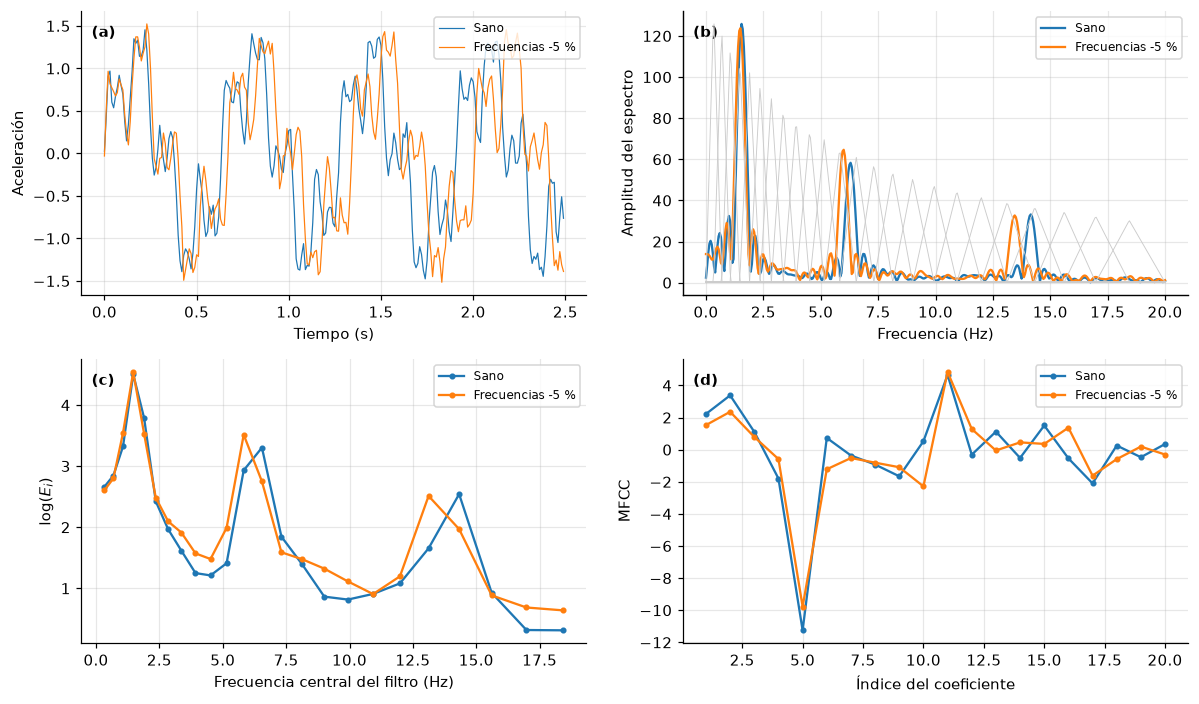

**Figura 4.** Cálculo de MFCC con señales sintéticas. (a) Señal. (b) Espectro remuestreado a 0–20 Hz, con el banco de filtros en gris. (c) Logaritmo de las energías de cada filtro, Ec. (4). (d) MFCC, Ec. (5). Un corrimiento de 5 % en las frecuencias cambia de forma visible los coeficientes.

In [5]:
S_KEEP = 20   # number of MFCCs kept, s (not reported in the paper)
FS = 100.0    # sampling frequency (Hz), as in the paper
NFFT = 2048   # zero-padded FFT length

# DCT matrix of Eq. (5): rows j = 2..N-1, columns i = 2..N-1
_i = np.arange(2, N_KEY)
_j = np.arange(2, N_KEY)
DCT = np.cos(np.pi / (N_KEY - 2) * np.outer(_j, _i - 1.5))


def mfcc_steps(acc, fs=FS):
    # Return every intermediate result of the MFCC pipeline for one signal
    acc_f = gaussian_filter1d(acc, sigma=0.5)                       # step 1: Gaussian filter
    spec = np.abs(np.fft.rfft(acc_f, NFFT))                         # step 2: FFT amplitude
    spec_f = np.interp(f_grid, np.fft.rfftfreq(NFFT, 1 / fs), spec)  # resample to 0-20 Hz
    log_e = np.log(H_mel @ spec_f * (f_grid[1] - f_grid[0]) + 1e-12)  # steps 3-4: Eq. (4)
    coeffs = DCT @ log_e                                            # step 5: Eq. (5)
    return spec_f, log_e, coeffs[:S_KEEP]


def mfcc(acc, fs=FS):
    return mfcc_steps(acc, fs)[2]


# Example: synthetic "bridge" signals, intact vs. 5 % lower frequencies
t = np.arange(0, 2.5, 1 / FS)
demo_rng = np.random.default_rng(SEED)
f_intact = np.array([1.57, 6.29, 14.15])
amps = np.array([1.0, 0.5, 0.3])
signals = {}
for name, freqs in [("Sano", f_intact), ("Frecuencias -5 %", 0.95 * f_intact)]:
    x = (amps[:, None] * np.sin(2 * np.pi * freqs[:, None] * t)).sum(0)
    signals[name] = x + 0.1 * x.std() * demo_rng.standard_normal(t.size)

fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
for name, x in signals.items():
    spec_f, log_e, c = mfcc_steps(x)
    axes[0, 0].plot(t, x, lw=0.8, label=name)
    axes[0, 1].plot(f_grid, spec_f, label=name)
    axes[1, 0].plot(key_hz[1:-1], log_e, "o-", ms=3, label=name)
    axes[1, 1].plot(np.arange(1, S_KEEP + 1), c, "o-", ms=3, label=name)
ax2 = axes[0, 1].twinx()
ax2.plot(f_grid, H_mel.T, color="0.8", lw=0.6)
ax2.set_yticks([])
ax2.grid(False)
axes[0, 0].set(xlabel="Tiempo (s)", ylabel="Aceleración")
axes[0, 1].set(xlabel="Frecuencia (Hz)", ylabel="Amplitud del espectro")
axes[1, 0].set(xlabel="Frecuencia central del filtro (Hz)", ylabel="$\\log(E_i)$")
axes[1, 1].set(xlabel="Índice del coeficiente", ylabel="MFCC")
for ax, tag in zip(axes.flat, "abcd"):
    ax.text(0.02, 0.95, f"({tag})", transform=ax.transAxes, fontweight="bold", va="top")
    ax.legend(fontsize=8, loc="upper right")
fig.tight_layout()
show_figure(fig, 4, "Cálculo de MFCC con señales sintéticas. (a) Señal. (b) Espectro remuestreado a 0–20 Hz, con el banco "
                    "de filtros en gris. (c) Logaritmo de las energías de cada filtro, Ec. (4). (d) MFCC, Ec. (5). "
                    "Un corrimiento de 5 % en las frecuencias cambia de forma visible los coeficientes.")

**Interpretación.** Una sola señal da un vector de $s$ números. Con muchos vehículos, cada puente queda descrito por una **nube de vectores MFCC** (la matriz $\mathbf{M}_i$). El daño desplaza esa nube; el siguiente paso mide ese desplazamiento.

<a id="kl"></a>
### 4.2 Divergencia KL entre dos puentes

Qué es la divergencia KL y por qué se eligió está en la [ficha 3.3](#c-kl). Aquí se ve la fórmula que usa el artículo para comparar la nube de MFCC de un puente con la de otro.

**Supuesto:** las filas de $\mathbf{M}_i$ siguen una distribución normal multivariada $\mathcal{N}(\boldsymbol{\mu}_i, \boldsymbol{\Sigma}_i)$. Con ese supuesto la divergencia tiene fórmula cerrada (Ec. 9 del artículo):

$$D_{KL}(\mathbf{M}_i \Vert \mathbf{M}_j) = \frac{1}{2}\left[\operatorname{tr}\!\left(\boldsymbol{\Sigma}_j^{-1}\boldsymbol{\Sigma}_i\right) + (\boldsymbol{\mu}_j - \boldsymbol{\mu}_i)^{T}\boldsymbol{\Sigma}_j^{-1}(\boldsymbol{\mu}_j - \boldsymbol{\mu}_i) - s + \ln\frac{\det \boldsymbol{\Sigma}_j}{\det \boldsymbol{\Sigma}_i}\right] \tag{6}$$

- $\operatorname{tr}(\boldsymbol{\Sigma}_j^{-1}\boldsymbol{\Sigma}_i)$: compara la **dispersión** de las dos nubes ($\operatorname{tr}$ es la traza).
- $(\boldsymbol{\mu}_j - \boldsymbol{\mu}_i)^{T}\boldsymbol{\Sigma}_j^{-1}(\boldsymbol{\mu}_j - \boldsymbol{\mu}_i)$: distancia entre los **centros**, medida en unidades de la dispersión (distancia de Mahalanobis al cuadrado).
- $\ln(\det\boldsymbol{\Sigma}_j / \det\boldsymbol{\Sigma}_i)$: compara el **volumen** de las nubes.
- $-s$: hace que $D_{KL} = 0$ cuando las dos distribuciones son iguales.

**No es simétrica:** $D_{KL}(\mathbf{M}_i \Vert \mathbf{M}_j) \neq D_{KL}(\mathbf{M}_j \Vert \mathbf{M}_i)$, por eso la matriz que se arma después no es simétrica (Figura 5).

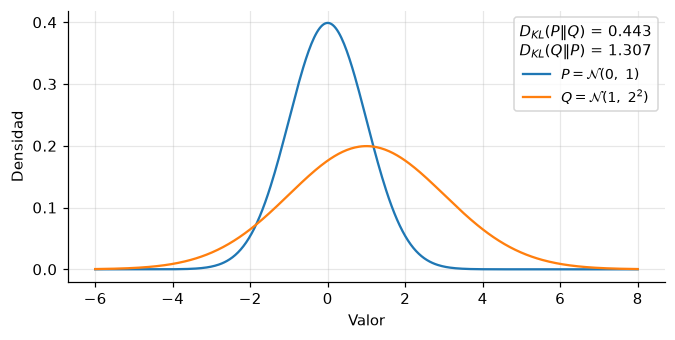

**Figura 5.** Divergencia KL entre dos normales en una dimensión, calculada con la Ec. (6). El valor cambia según el orden: la divergencia no es simétrica.

In [6]:
def gaussian_stats(M):
    # Mean vector, covariance, inverse covariance and log-determinant of MFCC matrix M (rows = vehicles)
    mu = M.mean(axis=0)
    cov = np.cov(M, rowvar=False)
    return mu, cov, np.linalg.inv(cov), np.linalg.slogdet(cov)[1]


def kl_gaussian(stats_i, stats_j):
    # Eq. (6): D_KL(N_i || N_j) between two multivariate normal distributions
    mu_i, cov_i, _, logdet_i = stats_i
    mu_j, _, inv_j, logdet_j = stats_j
    d = mu_j - mu_i
    return 0.5 * (np.trace(inv_j @ cov_i) + d @ inv_j @ d - len(mu_i) + logdet_j - logdet_i)


# 1D example: a narrow and a wide normal distribution
p_stats = (np.array([0.0]), np.array([[1.0]]), np.array([[1.0]]), 0.0)
q_stats = (np.array([1.0]), np.array([[4.0]]), np.array([[0.25]]), np.log(4.0))
x = np.linspace(-6, 8, 400)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(x, norm.pdf(x, 0, 1), label="$P = \\mathcal{N}(0,\\ 1)$")
ax.plot(x, norm.pdf(x, 1, 2), label="$Q = \\mathcal{N}(1,\\ 2^2)$")
ax.set(xlabel="Valor", ylabel="Densidad")
ax.legend(title=f"$D_{{KL}}(P \\Vert Q)$ = {kl_gaussian(p_stats, q_stats):.3f}\n"
                f"$D_{{KL}}(Q \\Vert P)$ = {kl_gaussian(q_stats, p_stats):.3f}", fontsize=9)
show_figure(fig, 5, "Divergencia KL entre dos normales en una dimensión, calculada con la Ec. (6). "
                    "El valor cambia según el orden: la divergencia no es simétrica.")

<a id="df"></a>
### 4.3 Factor de divergencia

Para cada par de puentes se calcula la KL y se transforma con un logaritmo (Ec. 10 del artículo):

$$DF[i,j] = \ln\!\left(D_{KL}(\mathbf{M}_i \Vert \mathbf{M}_j) + e\right) - 1 \tag{7}$$

donde $e$ es la constante de Euler. Con esto $DF = 0$ cuando $D_{KL} = 0$, y los valores grandes se comprimen (Tabla 3), de modo que un par de puentes muy distintos no domina la matriz. Con $m$ puentes se obtiene la **matriz de factores de divergencia** $DF$ de $m \times m$, con ceros en la diagonal.

In [7]:
def divergence_factor(d_kl):
    # Eq. (7)
    return np.log(d_kl + np.e) - 1.0


d_kl_values = np.array([0.0, 0.1, 1.0, 10.0, 100.0, 1000.0])
show_table(pd.DataFrame({"D_KL": d_kl_values, "DF": divergence_factor(d_kl_values)}), 3,
           "Efecto de la Ec. (7): la KL crece cuatro órdenes de magnitud y el DF solo pasa de 0 a ~6.",
           precision=3, hide_index=True)

**Tabla 3.** Efecto de la Ec. (7): la KL crece cuatro órdenes de magnitud y el DF solo pasa de 0 a ~6.

D_KL,DF
0.000,0.000
0.100,0.036
1.000,0.313
10.000,1.543
100.000,3.632
1000.000,5.910


<a id="rdi"></a>
### 4.4 PDM, factor de separación e índice de daño relativo (RDI)

**Idea.** Los puentes son distintos entre sí, así que $DF[i,j] \neq 0$ aun sin daño. Lo que indica daño es **cuánto cambia** $DF$ entre la línea base (puentes sanos) y el estado desconocido.

**Paso 1. Matriz de diferencia porcentual (PDM)** (Ec. 11 del artículo):

$$\Delta DF[i,j] = \frac{DF_{\text{unknown}}[i,j] - DF_{\text{baseline}}[i,j]}{DF_{\text{baseline}}[i,j] + \varepsilon} \times 100\,\% \tag{8}$$

donde $\varepsilon$ es la mediana de los elementos fuera de la diagonal de $DF_{\text{baseline}}$; evita dividir por valores cercanos a cero.

**Paso 2. Factor de separación** del puente $i$ (Ec. 12 del artículo): suma de su fila y su columna en la PDM, dividida por la suma de toda la matriz.

$$SF_i = \frac{\sum_{k=1}^{m} \Delta DF[i,k] + \sum_{k=1,\,k\neq i}^{m} \Delta DF[k,i]}{\sum_{h=1}^{m}\sum_{k=1}^{m} \Delta DF[h,k]} \tag{9}$$

**Paso 3. Índice de daño relativo** (Ec. 13 del artículo):

$$RDI_i = e^{SF_i} - 1 \tag{10}$$

**Por qué funciona.** Si un puente se daña, cambian **su fila y su columna** de la PDM (se forma una "cruz"), y su $SF_i$ crece. Si nadie se daña, los cambios se reparten y $SF_i \approx 2/m$ para todos (con $m = 12$, $RDI \approx e^{1/6} - 1 = 0.18$). El RDI es **relativo**: mide qué parte del cambio total de la red corresponde a cada puente.

> El artículo no dice si en la Ec. (8) se toma el valor absoluto. Sus PDM (Figs. 9–11) solo muestran valores positivos, así que aquí se usa $|\Delta DF|$.

En el ejemplo de la Figura 6 hay 6 puentes ficticios con MFCC de 2 coeficientes; en el estado desconocido, el puente 3 desplaza su nube.

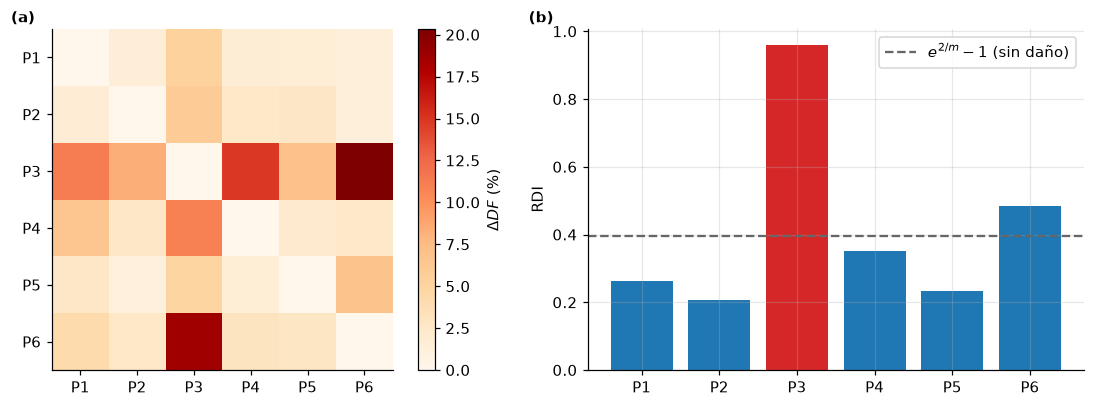

**Figura 6.** Ejemplo con 6 puentes ficticios en el que solo cambia P3. (a) PDM, Ec. (8): la fila y la columna de P3 forman una cruz. (b) RDI, Ec. (10): P3 se separa claramente del valor esperado sin daño; P6 sube un poco porque su comparación con P3 es la que más cambia.

In [8]:
def divergence_factor_matrix(stats):
    # DF[i, j] for every ordered pair of bridges (zeros on the diagonal)
    m = len(stats)
    DF = np.zeros((m, m))
    for i in range(m):
        for j in range(m):
            if i != j:
                DF[i, j] = divergence_factor(kl_gaussian(stats[i], stats[j]))
    return DF


def relative_damage_index(DF_base, DF_unknown):
    # Eq. (8): stabilized percentage difference matrix (absolute value)
    off_diag = ~np.eye(len(DF_base), dtype=bool)
    eps = np.median(DF_base[off_diag])
    PDM = np.abs(DF_unknown - DF_base) / (DF_base + eps) * 100.0
    # Eq. (9): row sum + column sum (without the diagonal) over the total sum
    SF = (PDM.sum(axis=1) + PDM.sum(axis=0) - np.diag(PDM)) / PDM.sum()
    # Eq. (10)
    return np.exp(SF) - 1.0, PDM


# Toy network: 6 bridges, 2 MFCCs each, 400 vehicles per bridge
toy_rng = np.random.default_rng(SEED)
centers = toy_rng.uniform(-3, 3, size=(6, 2))
toy_base = [gaussian_stats(c + toy_rng.standard_normal((400, 2))) for c in centers]
shift = np.zeros((6, 2))
shift[2] = [0.6, -0.4]          # bridge 3 is "damaged" in the unknown state
toy_unknown = [gaussian_stats(c + s + toy_rng.standard_normal((400, 2))) for c, s in zip(centers, shift)]
toy_rdi, toy_pdm = relative_damage_index(divergence_factor_matrix(toy_base), divergence_factor_matrix(toy_unknown))

labels = [f"P{k}" for k in range(1, 7)]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
im = axes[0].imshow(toy_pdm, cmap="OrRd")
axes[0].set_xticks(range(6), labels)
axes[0].set_yticks(range(6), labels)
axes[0].grid(False)
fig.colorbar(im, ax=axes[0], label="$\\Delta DF$ (%)")
axes[1].bar(labels, toy_rdi, color=["C3" if k == 2 else "C0" for k in range(6)])
axes[1].axhline(np.exp(2 / 6) - 1, color="0.4", ls="--", label="$e^{2/m}-1$ (sin daño)")
axes[1].set_ylabel("RDI")
axes[1].legend()
for ax, tag in zip(axes, "ab"):
    ax.text(-0.12, 1.02, f"({tag})", transform=ax.transAxes, fontweight="bold")
fig.tight_layout()
show_figure(fig, 6, "Ejemplo con 6 puentes ficticios en el que solo cambia P3. (a) PDM, Ec. (8): la fila y la columna de P3 "
                    "forman una cruz. (b) RDI, Ec. (10): P3 se separa claramente del valor esperado sin daño; P6 sube un poco "
                    "porque su comparación con P3 es la que más cambia.")

<a id="umbral"></a>
### 4.5 Umbral de detección

Cada puente tiene su propio umbral, obtenido **solo con datos sanos** mediante validación cruzada:

1. Los datos de línea base (1000 vehículos por puente) se dividen al azar en dos mitades: una hace de "línea base" y la otra de "estado desconocido" sano (validación).
2. Se calcula el RDI de cada puente. Se repite muchas veces, con divisiones distintas.
3. El umbral es (Ec. 14 del artículo):

$$\text{umbral}_i = \overline{RDI}_{i,\text{val}} + 2.5\,\sigma\!\left(RDI_{i,\text{val}}\right) \tag{11}$$

donde $\overline{RDI}_{i,\text{val}}$ y $\sigma(RDI_{i,\text{val}})$ son la media y la desviación estándar de los RDI de validación del puente $i$.

4. **Decisión:** el puente $i$ se declara dañado si $RDI_i > \text{umbral}_i$, es decir, si $RDI_i/\text{umbral}_i > 1$.

El factor 2.5 es una elección de los autores: si el RDI sano fuera normal, se esperaría cerca de 0.6 % de falsas alarmas por puente.

<a id="procedimiento"></a>
## 5. Procedimiento

Todo el estudio es **numérico** (Sección 3 del artículo): no hay datos de campo ni de laboratorio. Se simula una red de 12 puentes, vehículos aleatorios que los cruzan, la interacción vehículo–puente y la aceleración que mediría un teléfono dentro de cada vehículo. En cada paso se indica qué hizo el artículo y qué hace la simulación simplificada de este notebook.

<a id="red"></a>
### 5.1 Red de 12 puentes

Los 12 puentes combinan 3 luces ($L$ = 25, 27.5 y 30 m), 2 áreas ($A$ = 2.00 y 2.25 m²) y 2 inercias ($I$ = 0.10 y 0.12 m⁴). Todos son de concreto: $E = 27.5$ GPa, $\rho = 2400$ kg/m³ y amortiguamiento $\zeta = 1.5\,\%$ (Tablas 1 y 2 del artículo).

Las frecuencias que reporta el artículo coinciden con las de una **viga simplemente apoyada de Euler–Bernoulli**:

$$f_n = \frac{n^2\pi}{2L^2}\sqrt{\frac{EI}{\rho A}} \tag{12}$$

donde $f_n$ es la frecuencia del modo $n$ (Hz), $E$ el módulo de elasticidad, $I$ la inercia, $\rho$ la densidad y $A$ el área. La Tabla 4 lo comprueba.

In [9]:
E_MOD, RHO, ZETA_B, GRAVITY = 27.5e9, 2400.0, 0.015, 9.81

# (length, area, inertia) of Bridge-1 ... Bridge-12 (paper, Table 2)
BRIDGES = [(L, A, I) for L in (25.0, 27.5, 30.0) for A in (2.00, 2.25) for I in (0.10, 0.12)]
M_BRIDGES = len(BRIDGES)
BRIDGE_NAMES = [f"Puente {k}" for k in range(1, M_BRIDGES + 1)]

# Natural frequencies reported in the paper (Table 2): f1, f2, f3 (Hz)
PAPER_FREQS = np.array([
    [1.902, 7.609, 17.121], [2.084, 8.336, 18.755], [1.794, 7.174, 16.142], [1.965, 7.859, 17.682],
    [1.572, 6.289, 14.150], [1.722, 6.889, 15.500], [1.482, 5.929, 13.340], [1.624, 6.495, 14.614],
    [1.321, 5.284, 11.890], [1.447, 5.789, 13.024], [1.246, 4.982, 11.210], [1.364, 5.458, 12.279]])


def analytic_freqs(L, A, I, n_modes=3):
    n = np.arange(1, n_modes + 1)
    return n**2 * np.pi / (2 * L**2) * np.sqrt(E_MOD * I / (RHO * A))   # Eq. (12)


table = pd.DataFrame(BRIDGES, columns=["L (m)", "A (m²)", "I (m⁴)"], index=BRIDGE_NAMES)
analytic = np.array([analytic_freqs(*b) for b in BRIDGES])
for n in range(3):
    table[f"f{n + 1} Ec. (12)"] = analytic[:, n]
    table[f"f{n + 1} artículo"] = PAPER_FREQS[:, n]
show_table(table, 4, "Puentes simulados: geometría y frecuencias naturales calculadas con la Ec. (12) frente a las "
                     "reportadas en la Tabla 2 del artículo (Hz).", precision=3)

**Tabla 4.** Puentes simulados: geometría y frecuencias naturales calculadas con la Ec. (12) frente a las reportadas en la Tabla 2 del artículo (Hz).

,L (m),A (m²),I (m⁴),f1 Ec. (12),f1 artículo,f2 Ec. (12),f2 artículo,f3 Ec. (12),f3 artículo
Puente 1,25.000,2.000,0.100,1.902,1.902,7.609,7.609,17.121,17.121
Puente 2,25.000,2.000,0.120,2.084,2.084,8.336,8.336,18.755,18.755
Puente 3,25.000,2.250,0.100,1.794,1.794,7.174,7.174,16.142,16.142
Puente 4,25.000,2.250,0.120,1.965,1.965,7.859,7.859,17.682,17.682
Puente 5,27.500,2.000,0.100,1.572,1.572,6.289,6.289,14.150,14.150
Puente 6,27.500,2.000,0.120,1.722,1.722,6.889,6.889,15.500,15.500
Puente 7,27.500,2.250,0.100,1.482,1.482,5.929,5.929,13.340,13.340
Puente 8,27.500,2.250,0.120,1.624,1.624,6.495,6.495,14.614,14.614
Puente 9,30.000,2.000,0.100,1.321,1.321,5.284,5.284,11.890,11.890
Puente 10,30.000,2.000,0.120,1.447,1.447,5.789,5.789,13.024,13.024


**Interpretación.** Las frecuencias coinciden con 3 decimales: los puentes del artículo son vigas simplemente apoyadas. Todos los $f_1$ están entre 1.25 y 2.08 Hz y todos los $f_3$ por debajo de 19 Hz, dentro de la banda de 0–20 Hz de los MFCC.

<a id="fe"></a>
### 5.2 Modelo de elementos finitos y escenarios de daño

**Artículo:** cada puente es un modelo de elementos finitos con 500 puntos de discretización. El daño es una **reducción local de rigidez** ($EI$) en un tramo del puente 5; los demás puentes siguen sanos.

**Aquí:** viga de Euler–Bernoulli con 100 elementos (rigidez y masa consistentes de 4 grados de libertad cada uno), apoyos simples y los 4 primeros modos. El daño multiplica $EI$ por $(1-\alpha)$ en los elementos del tramo dañado. La Tabla 5 resume los escenarios.

**Tabla 5.** Escenarios de daño en el puente 5 (Secciones 3.3 y 4.5 del artículo).

| Escenario | Pérdida de rigidez $\alpha$ | Tramo dañado | Posición |
|---|---|---|---|
| Caso de daño 1 | 20 % | 10 % de la luz | Centro de luz |
| Caso de daño 2 | 40 % | 10 % de la luz | Centro de luz |
| Daño pequeño 1 | 10 % | 5 % de la luz | 1/4 de la luz |
| Daño pequeño 2 | 10 % + 10 % | 5 % + 5 % de la luz | 1/4 y 1/2 de la luz |

In [10]:
# Damage scenarios on Bridge-5: list of (center / L, length / L, stiffness loss)
DAMAGE = {
    "Sano": [],
    "Daño 1 (20 %)": [(0.50, 0.10, 0.20)],
    "Daño 2 (40 %)": [(0.50, 0.10, 0.40)],
    "Pequeño 1": [(0.25, 0.05, 0.10)],
    "Pequeño 2": [(0.25, 0.05, 0.10), (0.50, 0.05, 0.10)],
}
DAMAGED_BRIDGE = 4   # zero-based index of Bridge-5


def beam_modes(L, A, I, damage=(), n_el=100, n_modes=4):
    # Simply supported Euler-Bernoulli beam: natural frequencies (Hz) and mass-normalized mode shapes at the nodes
    le = L / n_el
    n_dof = 2 * (n_el + 1)
    K = np.zeros((n_dof, n_dof))
    M = np.zeros((n_dof, n_dof))
    x_mid = (np.arange(n_el) + 0.5) * le
    k_e = np.array([[12, 6 * le, -12, 6 * le], [6 * le, 4 * le**2, -6 * le, 2 * le**2],
                    [-12, -6 * le, 12, -6 * le], [6 * le, 2 * le**2, -6 * le, 4 * le**2]]) / le**3
    m_e = RHO * A * le / 420 * np.array([[156, 22 * le, 54, -13 * le], [22 * le, 4 * le**2, 13 * le, -3 * le**2],
                                        [54, 13 * le, 156, -22 * le], [-13 * le, -3 * le**2, -22 * le, 4 * le**2]])
    for e in range(n_el):
        EI = E_MOD * I
        for center, length, loss in damage:
            if abs(x_mid[e] - center * L) <= length * L / 2:
                EI *= 1.0 - loss
        dofs = slice(2 * e, 2 * e + 4)
        K[dofs, dofs] += EI * k_e
        M[dofs, dofs] += m_e
    free = np.setdiff1d(np.arange(n_dof), [0, n_dof - 2])   # pinned supports: no vertical displacement
    w2, V = eigh(K[np.ix_(free, free)], M[np.ix_(free, free)], subset_by_index=[0, n_modes - 1])
    phi = np.zeros((n_dof, n_modes))
    phi[free] = V
    return np.sqrt(w2) / (2 * np.pi), phi[0::2], np.linspace(0, L, n_el + 1)


freq_table = {}
for name, dmg in DAMAGE.items():
    freq_table[name] = beam_modes(*BRIDGES[DAMAGED_BRIDGE], damage=dmg)[0][:3]
freq_df = pd.DataFrame(freq_table, index=["f1 (Hz)", "f2 (Hz)", "f3 (Hz)"]).T
for n in range(3):
    freq_df[f"Δf{n + 1} (%)"] = (freq_df.iloc[:, n] / freq_df.iloc[0, n] - 1) * 100
show_table(freq_df, 6, "Frecuencias del puente 5 (modelo de elementos finitos de este notebook) para cada escenario "
                       "de daño y su cambio respecto al estado sano.", precision=3)

**Tabla 6.** Frecuencias del puente 5 (modelo de elementos finitos de este notebook) para cada escenario de daño y su cambio respecto al estado sano.

,f1 (Hz),f2 (Hz),f3 (Hz),Δf1 (%),Δf2 (%),Δf3 (%)
Sano,1.572,6.289,14.150,0.000,0.000,0.000
Daño 1 (20 %),1.535,6.284,13.845,-2.392,-0.081,-2.156
Daño 2 (40 %),1.477,6.275,13.424,-6.030,-0.215,-5.129
Pequeño 1,1.568,6.254,14.108,-0.268,-0.544,-0.297
Pequeño 2,1.559,6.254,14.032,-0.814,-0.549,-0.834


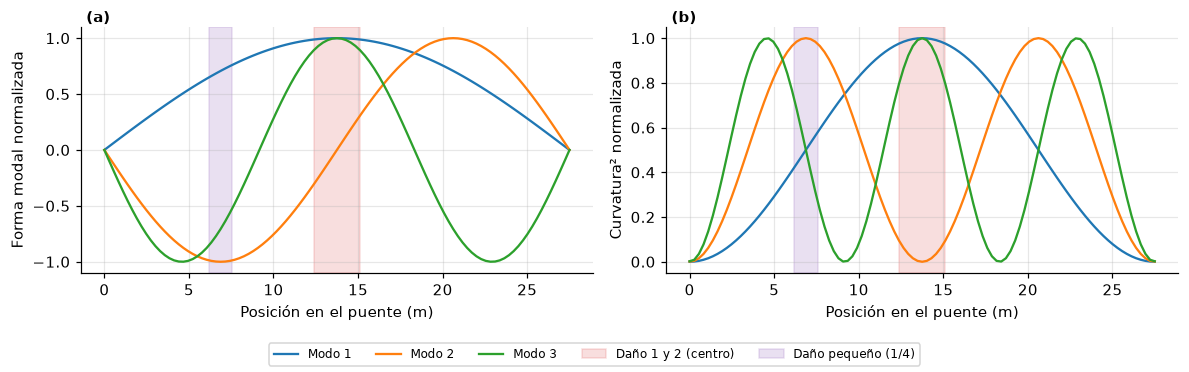

**Figura 7.** Puente 5. (a) Primeras tres formas modales. (b) Curvatura al cuadrado de cada modo, que indica dónde una pérdida de rigidez reduce más la frecuencia. Las franjas marcan las zonas dañadas.

In [11]:
f_b5, phi_b5, x_nodes = beam_modes(*BRIDGES[DAMAGED_BRIDGE])
L5 = BRIDGES[DAMAGED_BRIDGE][0]
curvature = np.gradient(np.gradient(phi_b5, x_nodes, axis=0), x_nodes, axis=0)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
for n in range(3):
    axes[0].plot(x_nodes, phi_b5[:, n] / np.abs(phi_b5[:, n]).max(), label=f"Modo {n + 1} ({f_b5[n]:.2f} Hz)")
    axes[1].plot(x_nodes, (curvature[:, n] / np.abs(curvature[:, n]).max())**2, label=f"Modo {n + 1}")
for ax in axes:
    ax.axvspan(0.45 * L5, 0.55 * L5, color="C3", alpha=0.15, label="Daño 1 y 2 (centro)")
    ax.axvspan(0.225 * L5, 0.275 * L5, color="C4", alpha=0.2, label="Daño pequeño (1/4)")
    ax.set_xlabel("Posición en el puente (m)")
axes[0].set_ylabel("Forma modal normalizada")
axes[1].set_ylabel("Curvatura² normalizada")
handles, leg_labels = axes[1].get_legend_handles_labels()
fig.legend(handles, leg_labels, loc="lower center", ncol=5, fontsize=8)
for ax, tag in zip(axes, "ab"):
    ax.text(0.01, 1.02, f"({tag})", transform=ax.transAxes, fontweight="bold")
fig.tight_layout(rect=(0, 0.08, 1, 1))
show_figure(fig, 7, "Puente 5. (a) Primeras tres formas modales. (b) Curvatura al cuadrado de cada modo, que indica dónde "
                    "una pérdida de rigidez reduce más la frecuencia. Las franjas marcan las zonas dañadas.")

**Interpretación.**

- Una pérdida de rigidez baja más la frecuencia de un modo cuanto mayor es la **curvatura** del modo en la zona dañada (Figura 7b).
- El daño en el **centro de luz** afecta a los modos 1 y 3, que tienen curvatura máxima allí, y casi nada al modo 2, que tiene curvatura nula en el centro. Con 40 % de pérdida, $f_1$ baja cerca de 6 % (Tabla 6).
- El daño a **1/4 de la luz** afecta poco a $f_1$; por eso el artículo lo considera "más difícil de detectar". Aun así, cambia algo $f_2$.
- Los cambios de frecuencia son **pequeños** (de 0.1 % a 6 %): el método debe detectar corrimientos menores que la resolución espectral de una sola señal de 2–3 s (0.3–0.5 Hz). Lo logra porque promedia estadísticamente sobre cientos de vehículos.

<a id="vehiculos"></a>
### 5.3 Vehículos aleatorios

Cada vehículo es un **cuarto de carro** (*quarter car*): una masa $m_v$ sobre un resorte $k_s$ y un amortiguador $c_s$ (Fig. 5 del artículo). Sus propiedades y su velocidad $v$ se sortean de **normales truncadas** (Tabla 3 del artículo), con 1000 vehículos distintos por puente y por estado. El artículo supone que **la distribución del tráfico es la misma en todos los puentes**.

**Tabla 7.** Distribuciones de los parámetros de los vehículos (Tabla 3 del artículo).

| Parámetro | Media | Desv. estándar | Mín. | Máx. | Unidad |
|---|---|---|---|---|---|
| Masa $m_v$ | 1000 | 50 | 800 | 1200 | kg |
| Rigidez $k_s$ | 90 000 | 1000 | 80 000 | 100 000 | N/m |
| Velocidad $v$ | 12.5 | 1.25 | 10 | 15 | m/s |
| Amortiguamiento $c_s$ | 5000 | 250 | 4000 | 6000 | N·s/m |

La frecuencia propia y el amortiguamiento del vehículo son

$$f_v = \frac{1}{2\pi}\sqrt{\frac{k_s}{m_v}}, \qquad \zeta_v = \frac{c_s}{2\sqrt{k_s m_v}} \tag{13}$$

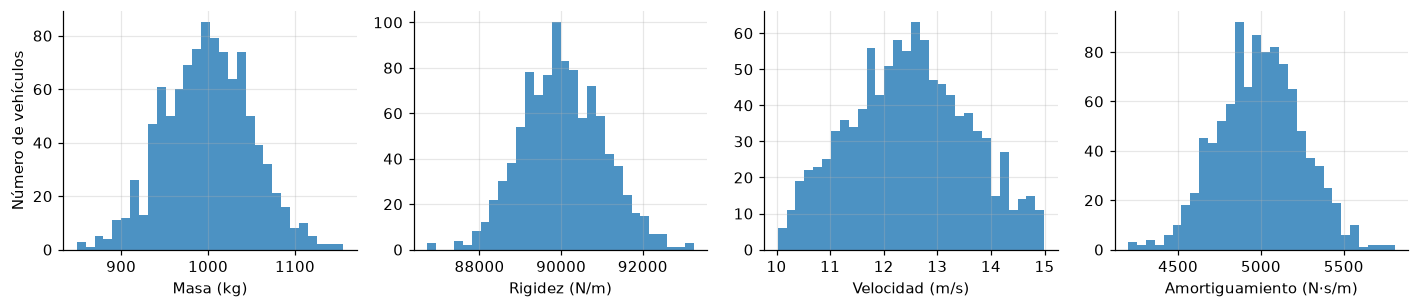

**Figura 8.** Parámetros de 1000 vehículos sorteados de las distribuciones de la Tabla 7 (equivalente a la Fig. 8 del artículo). Con la Ec. (13): $f_v$ = 1.51 ± 0.04 Hz y $\zeta_v$ = 0.26.

In [12]:
VEHICLE_DIST = {   # name: (mean, std, min, max)
    "m": (1000.0, 50.0, 800.0, 1200.0),
    "k": (90_000.0, 1000.0, 80_000.0, 100_000.0),
    "v": (12.5, 1.25, 10.0, 15.0),
    "c": (5000.0, 250.0, 4000.0, 6000.0),
}


def sample_vehicles(p, rng):
    # Truncated normal samples of mass, stiffness, speed and damping for p vehicles
    out = {}
    for name, (mean, std, lo, hi) in VEHICLE_DIST.items():
        out[name] = truncnorm.rvs((lo - mean) / std, (hi - mean) / std, loc=mean, scale=std,
                                  size=p, random_state=rng)
    return out


example_fleet = sample_vehicles(1000, np.random.default_rng(SEED))
f_v = np.sqrt(example_fleet["k"] / example_fleet["m"]) / (2 * np.pi)
zeta_v = example_fleet["c"] / (2 * np.sqrt(example_fleet["k"] * example_fleet["m"]))

fig, axes = plt.subplots(1, 4, figsize=(13, 2.9))
units = {"m": "Masa (kg)", "k": "Rigidez (N/m)", "v": "Velocidad (m/s)", "c": "Amortiguamiento (N·s/m)"}
for ax, (name, label) in zip(axes, units.items()):
    ax.hist(example_fleet[name], bins=30, color="C0", alpha=0.8)
    ax.set_xlabel(label)
axes[0].set_ylabel("Número de vehículos")
fig.tight_layout()
show_figure(fig, 8, f"Parámetros de 1000 vehículos sorteados de las distribuciones de la Tabla 7 (equivalente a la Fig. 8 "
                    f"del artículo). Con la Ec. (13): $f_v$ = {f_v.mean():.2f} ± {f_v.std():.2f} Hz y "
                    f"$\\zeta_v$ = {zeta_v.mean():.2f}.")

**Interpretación.** La frecuencia del vehículo (≈ 1.5 Hz) cae **dentro del rango de $f_1$ de los puentes** (1.25–2.08 Hz), así que en el espectro del vehículo se mezclan la respuesta propia del auto y la del puente. MISHM no intenta separarlas: compara las distribuciones de MFCC, que contienen ambas.

<a id="vbi"></a>
### 5.4 Interacción vehículo–puente (VBI)

**Artículo** (Figs. 5 y 6): análisis iterativo en OpenSees. En cada paso de tiempo se aplica la fuerza de contacto al puente, se obtiene el desplazamiento del puente bajo la rueda, ese desplazamiento excita al vehículo y se actualiza la fuerza hasta que converge. Además, cada simulación incluye de 15 a 25 vehículos de **tráfico de fondo**.

**Aquí:** modelo acoplado resuelto directamente (sin iterar) por superposición modal, con un solo vehículo por cruce y sin tráfico de fondo. Con $y$ el desplazamiento vertical del vehículo, $q_n$ la coordenada del modo $n$ del puente, $\phi_n(x)$ su forma modal (normalizada a masa unitaria), $\omega_n = 2\pi f_n$, $x = vt$ la posición de la rueda y $r(x)$ la rugosidad del pavimento:

$$u_c = \sum_n \phi_n(x)\,q_n + r(x), \qquad F_s = k_s\,(u_c - y) + c_s\,(\dot{u}_c - \dot{y}) \tag{14}$$

$$m_v\,\ddot{y} = F_s, \qquad \ddot{q}_n + 2\zeta\omega_n\dot{q}_n + \omega_n^2 q_n = -\phi_n(x)\left(m_v g + F_s\right) \tag{15}$$

donde $u_c$ es el desplazamiento del punto de contacto, $F_s$ la fuerza de la suspensión y $g$ la gravedad. La aceleración que registra el teléfono es $\ddot{y}$. Se integra con Runge–Kutta de orden 4 con paso de 0.002 s y se guarda a 100 Hz.

**Rugosidad.** El artículo genera un perfil de rugosidad "de bajo nivel" por puente con el método de la densidad espectral de potencia (PSD). Aquí se usa una PSD $G_d(n) \propto n^{-2}$ ($n$: frecuencia espacial, ciclos/m) escalada a la desviación estándar de la Fig. 7 del artículo ($\sigma \approx 0.085$ mm).

In [13]:
ROUGH_STD = 8.5e-5   # m, close to Fig. 7 of the paper


def road_profile(L, rng, dx=0.05):
    # Random road roughness with PSD proportional to n^-2, scaled to ROUGH_STD
    x = np.arange(0.0, L + dx, dx)
    n = np.fft.rfftfreq(x.size, dx)
    n[0] = n[1]
    amp = np.sqrt((n / 0.1) ** -2.0)
    r = np.fft.irfft(amp * np.exp(1j * rng.uniform(0, 2 * np.pi, n.size)), x.size)
    r -= r.mean()
    return x, r * ROUGH_STD / r.std()


def simulate_crossings(bridge, fleet, road, damage=(), noise=0.10, rng=None, fs=FS, substeps=5):
    # Vehicle body accelerations (one array per vehicle) for single crossings of one bridge, Eqs. (14)-(15)
    L = bridge[0]
    freqs, phi, x_nodes = beam_modes(*bridge, damage=damage)
    w = 2 * np.pi * freqs
    x_r, r = road
    dr = np.gradient(r, x_r)
    m, k, c, v = fleet["m"], fleet["k"], fleet["c"], fleet["v"]
    p, n_modes = m.size, w.size
    dt = 1.0 / fs / substeps
    t_cross = L / v
    n_steps = int(np.ceil(t_cross.max() / dt)) + 1

    def rhs(t, y, yd, q, qd):
        x = v * t
        on = x <= L                                                   # wheel still on the bridge
        Phi = np.stack([np.interp(x, x_nodes, phi[:, n]) for n in range(n_modes)], axis=1) * on[:, None]
        uc = (Phi * q).sum(1) + np.interp(x, x_r, r) * on
        ucd = (Phi * qd).sum(1) + np.interp(x, x_r, dr) * v * on
        Fs = k * (uc - y) + c * (ucd - yd)                            # Eq. (14)
        ydd = Fs / m                                                  # Eq. (15), vehicle
        qdd = -2 * ZETA_B * w * qd - w**2 * q - Phi * ((m * GRAVITY + Fs) * on)[:, None]   # Eq. (15), bridge
        return yd, ydd, qd, qdd

    state = [np.zeros(p), np.zeros(p), np.zeros((p, n_modes)), np.zeros((p, n_modes))]
    acc = []
    for step in range(n_steps):   # classic 4th-order Runge-Kutta
        t = step * dt
        k1 = rhs(t, *state)
        k2 = rhs(t + dt / 2, *[s + dt / 2 * d for s, d in zip(state, k1)])
        k3 = rhs(t + dt / 2, *[s + dt / 2 * d for s, d in zip(state, k2)])
        k4 = rhs(t + dt, *[s + dt * d for s, d in zip(state, k3)])
        if step % substeps == 0:
            acc.append(k1[1])
        state = [s + dt / 6 * (a + 2 * b + 2 * cc + d) for s, a, b, cc, d in zip(state, k1, k2, k3, k4)]
    acc = np.array(acc).T

    signals = []
    for i in range(p):   # keep only the time on the bridge and add 10 % noise
        a = acc[i, :int(t_cross[i] * fs)]
        signals.append(a + noise * a.std() * rng.standard_normal(a.size))
    return signals

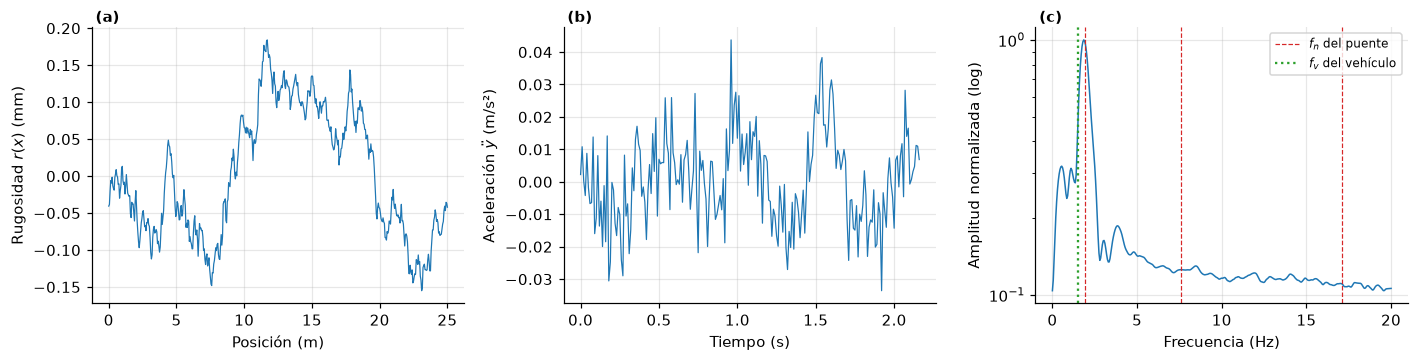

**Figura 9.** Simulación VBI en el puente 1. (a) Perfil de rugosidad. (b) Aceleración de un vehículo durante el cruce, con 10 % de ruido. (c) Espectro promedio de 300 cruces (escala logarítmica), con las tres primeras frecuencias del puente y la frecuencia media del vehículo.

In [14]:
demo_rng = np.random.default_rng(SEED)
demo_road = road_profile(BRIDGES[0][0], demo_rng)
demo_fleet = sample_vehicles(300, demo_rng)
demo_signals = simulate_crossings(BRIDGES[0], demo_fleet, demo_road, rng=demo_rng)

# Average amplitude spectrum over all crossings (zero-padded, same grid as the MFCCs)
f_fft = np.fft.rfftfreq(NFFT, 1 / FS)
mean_spec = np.mean([np.interp(f_grid, f_fft, np.abs(np.fft.rfft(a, NFFT))) for a in demo_signals], axis=0)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
axes[0].plot(demo_road[0], demo_road[1] * 1000, lw=0.8)
axes[0].set(xlabel="Posición (m)", ylabel="Rugosidad $r(x)$ (mm)")
a0 = demo_signals[0]
axes[1].plot(np.arange(a0.size) / FS, a0, lw=0.8)
axes[1].set(xlabel="Tiempo (s)", ylabel="Aceleración $\\ddot{y}$ (m/s²)")
axes[2].semilogy(f_grid, mean_spec / mean_spec.max(), lw=1)
for n, fn in enumerate(PAPER_FREQS[0]):
    axes[2].axvline(fn, color="C3", ls="--", lw=0.8, label="$f_n$ del puente" if n == 0 else None)
axes[2].axvline(np.median(np.sqrt(demo_fleet["k"] / demo_fleet["m"]) / (2 * np.pi)), color="C2", ls=":", label="$f_v$ del vehículo")
axes[2].set(xlabel="Frecuencia (Hz)", ylabel="Amplitud normalizada (log)")
axes[2].legend(fontsize=8)
for ax, tag in zip(axes, "abc"):
    ax.text(0.01, 1.02, f"({tag})", transform=ax.transAxes, fontweight="bold")
fig.tight_layout()
show_figure(fig, 9, "Simulación VBI en el puente 1. (a) Perfil de rugosidad. (b) Aceleración de un vehículo durante el cruce, "
                    "con 10 % de ruido. (c) Espectro promedio de 300 cruces (escala logarítmica), con las tres primeras "
                    "frecuencias del puente y la frecuencia media del vehículo.")

**Interpretación.**

- En una sola señal (Figura 9b) el contenido del puente no se distingue a simple vista.
- Al promediar muchos cruces (Figura 9c) domina un pico en $f_1$ del puente (1.9 Hz), muy cerca de la frecuencia del vehículo. $f_2$ y $f_3$ no se distinguen: la suspensión atenúa las frecuencias altas y el 10 % de ruido las tapa. En este modelo, la información de daño está sobre todo en la zona de $f_1$.
- Esto justifica el enfoque estadístico: **un vehículo no basta; muchos sí**.

<a id="senales"></a>
### 5.5 Generación de señales y MFCC

**Artículo** (Sección 3.3): para cada puente y cada estado se simulan 1000 vehículos distintos. La aceleración vertical se registra a 100 Hz (muy por encima del doble de 20 Hz, el límite de Nyquist para la banda de interés) y se le suma 10 % de ruido. Cada señal se convierte en un vector MFCC.

**Aquí** se hace lo mismo con el modelo de la sección 5.4. Hay un estado de línea base (todos sanos) y cuatro estados de monitoreo; en cada uno, **solo el puente 5 está dañado** y los otros 11 se vuelven a simular sanos con vehículos nuevos.

**Tabla 8.** Diferencias entre la simulación del artículo y la de este notebook.

| Aspecto | Artículo | Este notebook |
|---|---|---|
| Modelo de puente | Elementos finitos, 500 puntos | Elementos finitos, 100 elementos, 4 modos |
| Interacción | Iterativa en OpenSees | Acoplada, por superposición modal (RK4) |
| Tráfico de fondo | 15–25 vehículos por simulación | No incluido |
| $N$ (frecuencias clave), $s$ (MFCC conservados) | No reportados | $N = 26$, $s = 20$ |
| Ensayos de validación cruzada | No reportado (se ven 5 por puente) | 30 |

La siguiente celda tarda alrededor de un minuto.

In [15]:
P_VEHICLES = 1000
sim_rng = np.random.default_rng(SEED)
roads = [road_profile(b[0], sim_rng) for b in BRIDGES]   # one fixed road profile per bridge

start = time.time()
mfcc_data = {}   # state -> list of MFCC matrices (P_VEHICLES x S_KEEP), one per bridge
for state, damage in DAMAGE.items():
    mfcc_data[state] = []
    for b, bridge in enumerate(BRIDGES):
        fleet = sample_vehicles(P_VEHICLES, sim_rng)
        sigs = simulate_crossings(bridge, fleet, roads[b], damage=damage if b == DAMAGED_BRIDGE else (), rng=sim_rng)
        mfcc_data[state].append(np.array([mfcc(a) for a in sigs]))
print(f"{len(DAMAGE)} estados x {M_BRIDGES} puentes x {P_VEHICLES} vehículos simulados en {time.time() - start:.0f} s")

5 estados x 12 puentes x 1000 vehículos simulados en 62 s


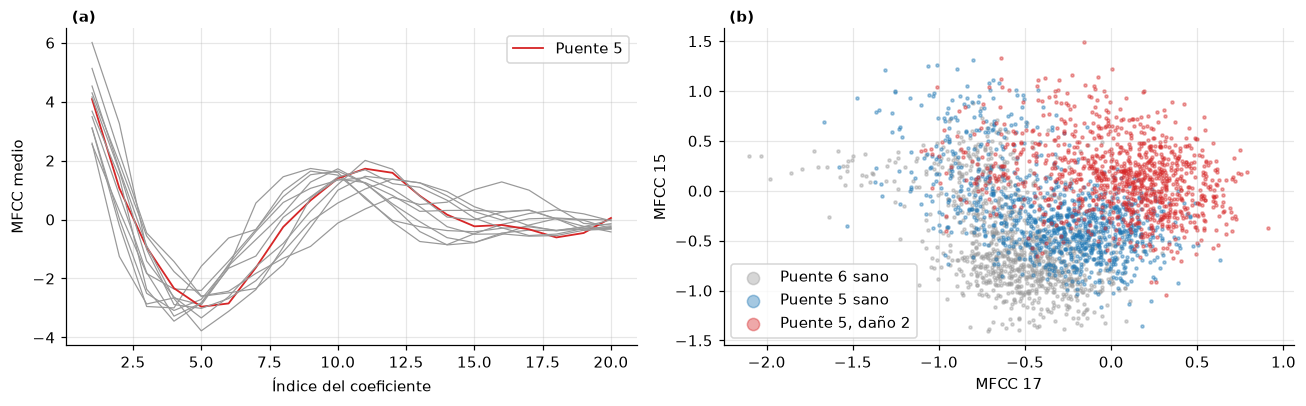

**Figura 10.** MFCC simulados. (a) Vector MFCC medio de los 12 puentes sanos: cada puente tiene su propia huella. (b) Nube de 1000 vehículos en los dos coeficientes más sensibles al daño: el daño 2 desplaza la nube del puente 5, pero las nubes se superponen mucho.

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
idx = np.arange(1, S_KEEP + 1)
for b in range(M_BRIDGES):
    axes[0].plot(idx, mfcc_data["Sano"][b].mean(0), lw=1.2 if b == DAMAGED_BRIDGE else 0.8,
                 color="C3" if b == DAMAGED_BRIDGE else "0.6", label="Puente 5" if b == DAMAGED_BRIDGE else None)
axes[0].set(xlabel="Índice del coeficiente", ylabel="MFCC medio")
axes[0].legend()

# Two coefficients that change the most for Bridge-5 under Damage 2 (standardized mean shift)
base5, dmg5 = mfcc_data["Sano"][DAMAGED_BRIDGE], mfcc_data["Daño 2 (40 %)"][DAMAGED_BRIDGE]
c1, c2 = np.argsort(-np.abs(dmg5.mean(0) - base5.mean(0)) / base5.std(0))[:2]
for M, label, color in [(mfcc_data["Sano"][5], "Puente 6 sano", "0.6"),
                        (base5, "Puente 5 sano", "C0"), (dmg5, "Puente 5, daño 2", "C3")]:
    axes[1].scatter(M[:, c1], M[:, c2], s=4, alpha=0.4, color=color, label=label)
axes[1].set(xlabel=f"MFCC {c1 + 1}", ylabel=f"MFCC {c2 + 1}")
axes[1].legend(markerscale=4)
for ax, tag in zip(axes, "ab"):
    ax.text(0.01, 1.02, f"({tag})", transform=ax.transAxes, fontweight="bold")
fig.tight_layout()
show_figure(fig, 10, "MFCC simulados. (a) Vector MFCC medio de los 12 puentes sanos: cada puente tiene su propia huella. "
                     "(b) Nube de 1000 vehículos en los dos coeficientes más sensibles al daño: el daño 2 desplaza la nube "
                     "del puente 5, pero las nubes se superponen mucho.")

**Interpretación.** Cada puente tiene su propia huella (Figura 10a), así que el valor absoluto de $DF[i,j]$ no indica daño: lo que importa es su **cambio** respecto a la línea base (Ec. 8). El daño desplaza la nube (Figura 10b), pero la superposición es grande: con un vehículo aislado no se puede decidir; la diferencia aparece en la estadística de cientos de cruces.

<a id="cv"></a>
### 5.6 Validación cruzada y prueba

En cada ensayo $t$ (30 ensayos):

1. Los 1000 vehículos sanos de cada puente se dividen al azar en dos mitades: **entrenamiento** (línea base, $DF_{\text{baseline}}$) y **validación**.
2. **Validación:** RDI de la mitad de validación frente a la línea base → distribución de RDI sanos → umbral, Ec. (11).
3. **Prueba:** se toman al azar 500 vehículos del estado de monitoreo (mismo tamaño que la línea base, porque la KL estimada depende del número de muestras) → RDI → cociente $RDI/\text{umbral}$.

In [17]:
N_TRIALS = 30
cv_rng = np.random.default_rng(SEED)
half = P_VEHICLES // 2

rdi_val, rdi_test, pdm_first = [], {s: [] for s in DAMAGE if s != "Sano"}, {}
for trial in range(N_TRIALS):
    perm = cv_rng.permutation(P_VEHICLES)
    train, val = perm[:half], perm[half:]
    DF_base = divergence_factor_matrix([gaussian_stats(M[train]) for M in mfcc_data["Sano"]])
    rdi_v, pdm_v = relative_damage_index(DF_base, divergence_factor_matrix([gaussian_stats(M[val]) for M in mfcc_data["Sano"]]))
    rdi_val.append(rdi_v)
    if trial == 0:
        pdm_first["Validación"] = pdm_v
    for state in rdi_test:
        pick = cv_rng.choice(P_VEHICLES, half, replace=False)
        rdi_u, pdm_u = relative_damage_index(DF_base, divergence_factor_matrix([gaussian_stats(M[pick]) for M in mfcc_data[state]]))
        rdi_test[state].append(rdi_u)
        if trial == 0:
            pdm_first[state] = pdm_u

rdi_val = np.array(rdi_val)
threshold = rdi_val.mean(0) + 2.5 * rdi_val.std(0)                       # Eq. (11)
ratio = {state: np.array(v) / threshold for state, v in rdi_test.items()}
print("Umbral por puente:", np.round(threshold, 3))

Umbral por puente: [0.295 0.294 0.27  0.277 0.286 0.257 0.302 0.275 0.278 0.269 0.295 0.319]


<a id="resultados"></a>
## 6. Resultados

Cada resultado se presenta primero con la simulación de este notebook y después con lo que **reporta el artículo** (Sección 4).

<a id="res-pdm"></a>
### 6.1 Matrices de diferencia porcentual (PDM)

Se calcula la PDM, Ec. (8), en tres situaciones: validación (todos sanos), daño 1 y daño 2 en el puente 5 (Figs. 9–11 del artículo).

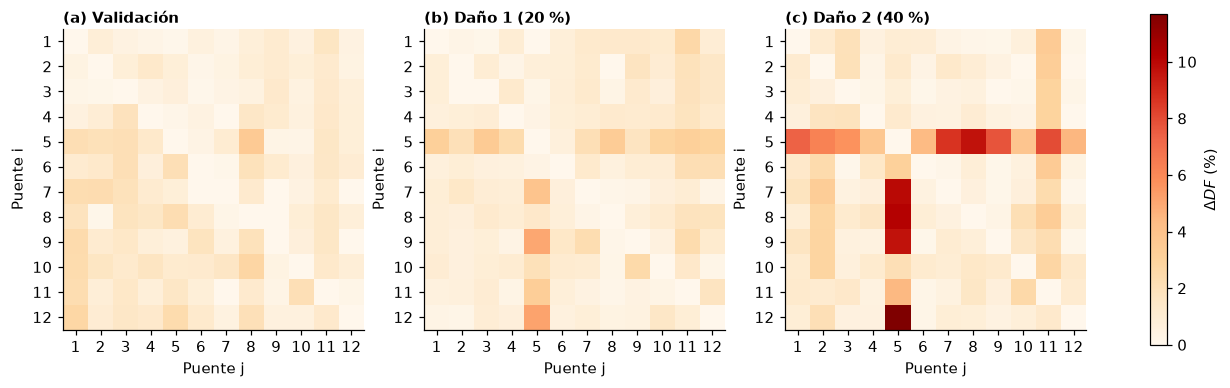

**Figura 11.** PDM simuladas (primer ensayo de validación cruzada). (a) Validación: sin patrón. (b) Daño 1 y (c) daño 2 en el puente 5: aparece una cruz en la fila y la columna 5, más intensa con más daño.

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
vmax = max(pdm_first[s].max() for s in ["Validación", "Daño 1 (20 %)", "Daño 2 (40 %)"])
short = [str(k) for k in range(1, M_BRIDGES + 1)]
for ax, state, tag in zip(axes, ["Validación", "Daño 1 (20 %)", "Daño 2 (40 %)"], "abc"):
    im = ax.imshow(pdm_first[state], cmap="OrRd", vmin=0, vmax=vmax)
    ax.set_xticks(range(M_BRIDGES), short)
    ax.set_yticks(range(M_BRIDGES), short)
    ax.set(xlabel="Puente j", ylabel="Puente i")
    ax.grid(False)
    ax.text(0.0, 1.02, f"({tag}) {state}", transform=ax.transAxes, fontweight="bold")
fig.colorbar(im, ax=axes, label="$\\Delta DF$ (%)", shrink=0.85)
show_figure(fig, 11, "PDM simuladas (primer ensayo de validación cruzada). (a) Validación: sin patrón. (b) Daño 1 y "
                     "(c) daño 2 en el puente 5: aparece una cruz en la fila y la columna 5, más intensa con más daño.")

**Reportado por el artículo (Figs. 9–11):**

- **Validación:** todos los elementos de la PDM son menores que 5 % (máximo 4.63 %), sin patrón.
- **Daño 1 (20 %):** la fila y la columna del puente 5 llegan hasta ~21 %; el resto sigue por debajo de ~6 %.
- **Daño 2 (40 %):** la cruz del puente 5 llega hasta ~35 % y casi todos sus elementos superan el 10 %.
- La matriz **no es simétrica** porque la KL no lo es; por eso el RDI suma la fila **y** la columna.

<a id="res-box"></a>
### 6.2 Distribución de las diferencias del puente 5

Se toman los 22 elementos de la fila y la columna del puente 5 en la PDM (sin la diagonal) y se resumen con diagramas de caja (Fig. 12 del artículo).

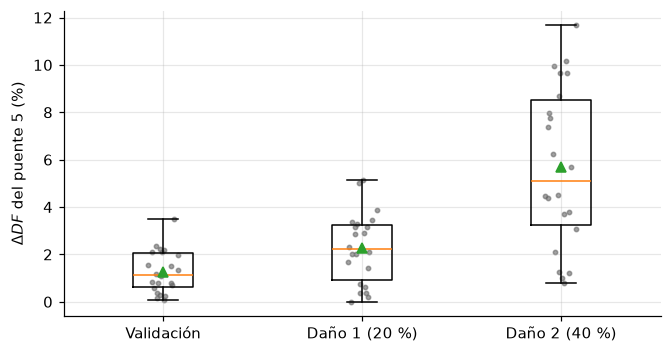

**Figura 12.** Distribución de los elementos de la PDM del puente 5 en la simulación (equivalente a la Fig. 12 del artículo).

**Tabla 9.** Mediana de las diferencias porcentuales del puente 5: simulación de este notebook frente a lo reportado en el artículo (Sección 4.2).

,Mediana simulada (%),Mediana del artículo (%)
Validación,1.1,2.0
Daño 1 (20 %),2.2,8.0
Daño 2 (40 %),5.1,17.5


In [19]:
def bridge_entries(pdm, b=DAMAGED_BRIDGE):
    # Row and column of bridge b without the diagonal
    mask = np.arange(M_BRIDGES) != b
    return np.concatenate([pdm[b, mask], pdm[mask, b]])


states_box = ["Validación", "Daño 1 (20 %)", "Daño 2 (40 %)"]
box_data = [bridge_entries(pdm_first[s]) for s in states_box]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.boxplot(box_data, tick_labels=states_box, showmeans=True)
for k, d in enumerate(box_data, start=1):
    ax.scatter(np.full(d.size, k) + np.random.default_rng(k).uniform(-0.08, 0.08, d.size), d, s=8, color="0.4", alpha=0.6)
ax.set_ylabel("$\\Delta DF$ del puente 5 (%)")
show_figure(fig, 12, "Distribución de los elementos de la PDM del puente 5 en la simulación (equivalente a la Fig. 12 del artículo).")

show_table(pd.DataFrame({"Mediana simulada (%)": [np.median(d) for d in box_data],
                         "Mediana del artículo (%)": [2.0, 8.0, 17.5]}, index=states_box), 9,
           "Mediana de las diferencias porcentuales del puente 5: simulación de este notebook frente a lo reportado "
           "en el artículo (Sección 4.2).", precision=1)

**Interpretación.** En los dos casos la mediana crece con la severidad del daño: el método no solo detecta, también **ordena** los daños por severidad. El artículo reporta medianas de ~2 % (validación), ~8 % (daño 1) y ~17.5 % (daño 2). Los valores de la simulación son distintos porque el modelo es más simple (Tabla 8), pero la tendencia es la misma.

<a id="res-rdi"></a>
### 6.3 RDI frente al umbral

Para cada puente y ensayo se grafica $RDI/\text{umbral}$; por encima de 1 el puente se declara dañado (Fig. 13 del artículo).

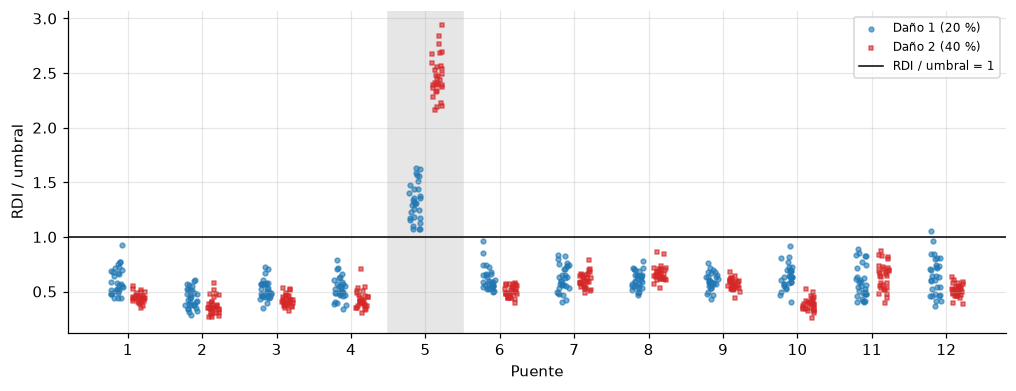

**Figura 13.** Cociente RDI/umbral simulado para los daños 1 y 2 en el puente 5 (franja gris), 30 ensayos por puente (equivalente a la Fig. 13 del artículo).

**Tabla 10.** Resumen de la simulación: cociente RDI/umbral del puente 5 y de los otros 11 puentes en los 30 ensayos.

,Puente 5: mín.,Puente 5: máx.,Puente 5: detectado (%),Otros: máx.,Otros: falsas alarmas (%)
Daño 1 (20 %),1.07,1.64,100.00,1.06,0.30
Daño 2 (40 %),2.17,2.94,100.00,0.87,0.00


In [20]:
def plot_ratios(ax, states, markers, colors):
    for k, (state, mk, col) in enumerate(zip(states, markers, colors)):
        r = ratio[state]
        for b in range(M_BRIDGES):
            xs = b + (k - 0.5) * 0.3 + np.random.default_rng(b).uniform(-0.08, 0.08, r.shape[0])
            ax.scatter(xs, r[:, b], s=10, marker=mk, color=col, alpha=0.6, label=state if b == 0 else None)
    ax.axhline(1.0, color="k", lw=1, label="RDI / umbral = 1")
    ax.axvspan(DAMAGED_BRIDGE - 0.5, DAMAGED_BRIDGE + 0.5, color="0.9", zorder=0)
    ax.set_xticks(range(M_BRIDGES), short)
    ax.set(xlabel="Puente", ylabel="RDI / umbral")
    ax.legend(fontsize=8, loc="upper right")


fig, ax = plt.subplots(figsize=(11, 3.8))
plot_ratios(ax, ["Daño 1 (20 %)", "Daño 2 (40 %)"], ["o", "s"], ["C0", "C3"])
show_figure(fig, 13, f"Cociente RDI/umbral simulado para los daños 1 y 2 en el puente 5 (franja gris), "
                     f"{N_TRIALS} ensayos por puente (equivalente a la Fig. 13 del artículo).")


def detection_summary(states):
    rows = {}
    for state in states:
        r = ratio[state]
        others = np.delete(r, DAMAGED_BRIDGE, axis=1)
        rows[state] = {"Puente 5: mín.": r[:, DAMAGED_BRIDGE].min(), "Puente 5: máx.": r[:, DAMAGED_BRIDGE].max(),
                       "Puente 5: detectado (%)": 100 * (r[:, DAMAGED_BRIDGE] > 1).mean(),
                       "Otros: máx.": others.max(), "Otros: falsas alarmas (%)": 100 * (others > 1).mean()}
    return pd.DataFrame(rows).T


show_table(detection_summary(["Daño 1 (20 %)", "Daño 2 (40 %)"]), 10,
           "Resumen de la simulación: cociente RDI/umbral del puente 5 y de los otros 11 puentes en los 30 ensayos.")

**Reportado por el artículo (Fig. 13):**

- **Daño 1:** todos los cocientes del puente 5 entre ~2.4 y ~2.8 → siempre detectado.
- **Daño 2:** entre ~3.5 y ~4.0 → siempre detectado y con cocientes mayores que en el daño 1.
- **Puentes sanos:** todos por debajo de ~0.8 → sin falsas alarmas.

**Interpretación.** El RDI separa al puente dañado del resto y crece con la severidad. En la simulación ambos daños se detectan en el 100 % de los ensayos, pero el daño 1 queda más cerca del umbral (≈ 1.1–1.6, frente a ≈ 2.4–2.8 en el artículo) y aparece alguna falsa alarma aislada en puentes sanos (≈ 0.3 % de los casos, Tabla 10). El margen de detección depende de detalles que el artículo no reporta ($N$, $s$, tráfico de fondo).

<a id="res-n"></a>
### 6.4 Influencia del número de vehículos

El artículo analiza cuánto varía el RDI del puente 5 según cuántos vehículos se usan (de 550 a 1000), con 30 ensayos por tamaño (Fig. 14 del artículo). La medida es el **coeficiente de variación**:

$$CV = \frac{\sigma(RDI_5)}{\overline{RDI}_5} \tag{16}$$

donde $\sigma$ y $\overline{RDI}_5$ son la desviación estándar y la media de los RDI del puente 5 en los 30 ensayos. Un $CV$ bajo significa un resultado estable.

En cada ensayo se usa la línea base completa (1000 vehículos sanos) y se toman al azar $n$ de los 1000 vehículos del estado dañado.

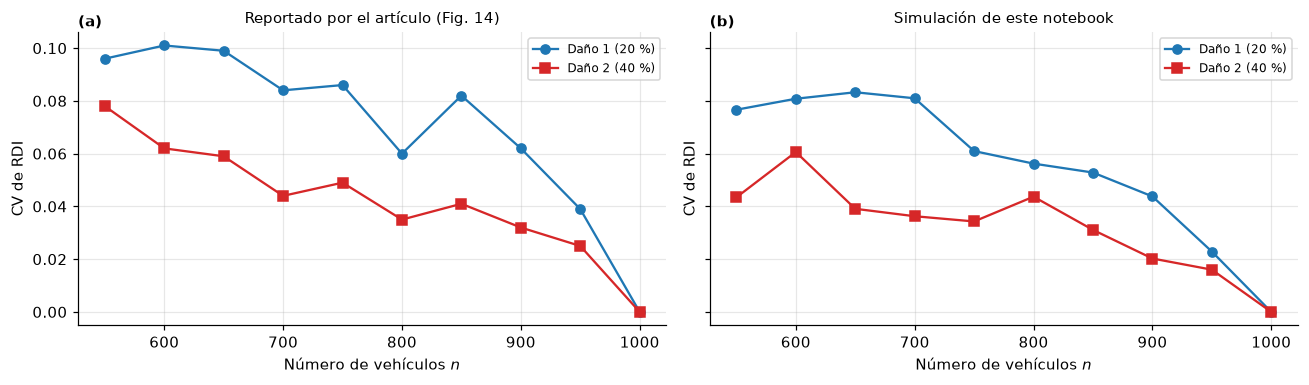

**Figura 14.** Coeficiente de variación del RDI del puente 5, Ec. (16), según el número de vehículos. (a) Valores reportados en la Fig. 14 del artículo. (b) Simulación de este notebook.

In [21]:
SIZES = np.arange(550, 1001, 50)
PAPER_CV = {"Daño 1 (20 %)": [0.096, 0.101, 0.099, 0.084, 0.086, 0.060, 0.082, 0.062, 0.039, 0.000],
            "Daño 2 (40 %)": [0.078, 0.062, 0.059, 0.044, 0.049, 0.035, 0.041, 0.032, 0.025, 0.000]}

n_rng = np.random.default_rng(SEED)
DF_base_full = divergence_factor_matrix([gaussian_stats(M) for M in mfcc_data["Sano"]])
sim_cv = {}
for state in PAPER_CV:
    sim_cv[state] = []
    for n in SIZES:
        rdis = []
        for _ in range(N_TRIALS):
            pick = n_rng.choice(P_VEHICLES, n, replace=False)
            DF_u = divergence_factor_matrix([gaussian_stats(M[pick]) for M in mfcc_data[state]])
            rdis.append(relative_damage_index(DF_base_full, DF_u)[0][DAMAGED_BRIDGE])
        sim_cv[state].append(np.std(rdis) / np.mean(rdis))   # Eq. (16)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for state, mk, col in [("Daño 1 (20 %)", "o", "C0"), ("Daño 2 (40 %)", "s", "C3")]:
    axes[0].plot(SIZES, PAPER_CV[state], marker=mk, color=col, label=state)
    axes[1].plot(SIZES, sim_cv[state], marker=mk, color=col, label=state)
axes[0].set_title("Reportado por el artículo (Fig. 14)", fontsize=10)
axes[1].set_title("Simulación de este notebook", fontsize=10)
for ax, tag in zip(axes, "ab"):
    ax.set(xlabel="Número de vehículos $n$", ylabel="CV de RDI")
    ax.legend(fontsize=8)
    ax.text(0.0, 1.02, f"({tag})", transform=ax.transAxes, fontweight="bold")
fig.tight_layout()
show_figure(fig, 14, "Coeficiente de variación del RDI del puente 5, Ec. (16), según el número de vehículos. "
                     "(a) Valores reportados en la Fig. 14 del artículo. (b) Simulación de este notebook.")

**Interpretación.**

- Con más vehículos el RDI es más estable (el CV baja): en el artículo pasa de ~0.10 a ~0.04 en el daño 1 y de ~0.08 a ~0.025 en el daño 2. El daño más severo da resultados más estables.
- El **CV = 0 con 1000 vehículos** no es un logro del método. Si se eligen 1000 de 1000 vehículos, los 30 ensayos usan exactamente los mismos datos y no hay variación. Lo mismo ocurre en la simulación: la caída hacia $n = 1000$ se debe en parte a que los ensayos comparten cada vez más vehículos.

<a id="res-small"></a>
### 6.5 Daños pequeños

Para buscar el límite de detección, el artículo prueba dos daños pequeños en el puente 5 (Tabla 5): 10 % de pérdida en 5 % de la luz a 1/4 de la luz, y el mismo daño más otro igual en el centro (Figs. 15 y 16 del artículo).

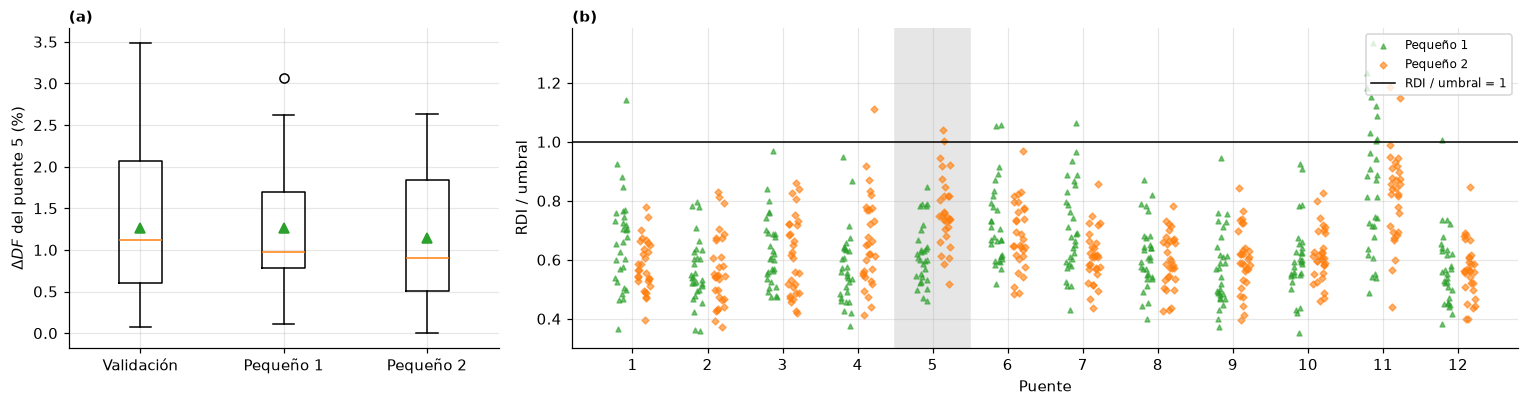

**Figura 15.** Daños pequeños en la simulación. (a) Diferencias porcentuales del puente 5 (equivalente a la Fig. 15 del artículo). (b) Cociente RDI/umbral (equivalente a la Fig. 16 del artículo).

**Tabla 11.** Resumen de la simulación para los daños pequeños (30 ensayos).

,Puente 5: mín.,Puente 5: máx.,Puente 5: detectado (%),Otros: máx.,Otros: falsas alarmas (%)
Pequeño 1,0.46,0.85,0.00,1.34,4.24
Pequeño 2,0.52,1.04,6.67,1.19,0.91


In [22]:
small_states = ["Pequeño 1", "Pequeño 2"]
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1, 2.2]})
box_small = [bridge_entries(pdm_first[s]) for s in ["Validación"] + small_states]
axes[0].boxplot(box_small, tick_labels=["Validación"] + small_states, showmeans=True)
axes[0].set_ylabel("$\\Delta DF$ del puente 5 (%)")
plot_ratios(axes[1], small_states, ["^", "D"], ["C2", "C1"])
for ax, tag in zip(axes, "ab"):
    ax.text(0.0, 1.02, f"({tag})", transform=ax.transAxes, fontweight="bold")
fig.tight_layout()
show_figure(fig, 15, "Daños pequeños en la simulación. (a) Diferencias porcentuales del puente 5 (equivalente a la Fig. 15 "
                     "del artículo). (b) Cociente RDI/umbral (equivalente a la Fig. 16 del artículo).")
show_table(detection_summary(small_states), 11, "Resumen de la simulación para los daños pequeños (30 ensayos).")

**Reportado por el artículo (Figs. 15–16):**

- Las medianas de las diferencias son muy parecidas: ~1.75 % (validación), ~2.15 % (pequeño 1) y ~2.2 % (pequeño 2). Agregar un segundo daño pequeño casi no cambia la respuesta global.
- Los cocientes RDI/umbral del puente 5 quedan **apenas por encima de 1** (~1.0–1.45), y algunos ensayos quedan en 1 o por debajo (~0.93).
- En la Fig. 16 del artículo, los puentes **sanos 3 y 6** tienen un ensayo cada uno **por encima de 1** (~1.03 y ~1.1): son **falsas alarmas** que el texto no comenta.

**En la simulación de este notebook** los daños pequeños **no se detectan**. Las diferencias del puente 5 no superan a las de validación (Figura 15a) y su cociente queda casi siempre por debajo de 1 (Tabla 11), mientras que algunos puentes sanos, sobre todo el 11, dan falsas alarmas. Los cambios de frecuencia son menores que 1 % (Tabla 6), demasiado pequeños para este modelo simplificado.

**Interpretación.** Este es el límite práctico del método: daños de ~10 % en tramos cortos están en el borde de lo detectable (en el artículo) o por debajo (en la simulación). A ese nivel aparecen tanto detecciones fallidas como falsas alarmas.

<a id="conclusiones"></a>
## 7. Conclusiones y limitaciones

### Conclusiones del artículo

1. MISHM detecta daño en un puente **comparándolo con toda la red**, usando solo aceleraciones de vehículos (MFCC + divergencia KL + RDI).
2. Distingue la severidad: mediana de la diferencia ~8 % con 20 % de pérdida de rigidez y ~17.5 % con 40 %. En ambos casos el RDI supera el umbral en todos los ensayos.
3. Las PDM son un **diagnóstico visual** inmediato: el puente dañado aparece como una cruz.
4. Con más vehículos, el RDI es más estable (menor CV): el método encaja con el *big data* del crowdsensing.
5. Daños pequeños (10 % en 5 % de la luz) quedan apenas por encima del umbral: el método sirve como **alerta temprana** a nivel de red, no para localizar el daño.

### Limitaciones declaradas por los autores

- No se incluyen efectos ambientales (temperatura, viento), que pueden causar falsas alarmas en la práctica.
- Escenarios de daño múltiple limitados.
- Falta validación en laboratorio y en campo (es el trabajo futuro).

### Limitaciones identificadas en este análisis

- **Solo simulación** y con condiciones favorables: rugosidad muy baja ($\sigma \approx 0.08$ mm), cuarto de carro de un eje, sin variaciones de temperatura ni de masa de los puentes.
- **Siempre hay un solo puente dañado.** Como el RDI es **relativo** (Ec. 9 divide por el cambio total de la red), varios puentes dañados a la vez se repartirían ese cambio y cada uno sobresaldría menos. Del mismo modo, un deterioro parejo en toda la red no se detectaría. Esto también podría verse como una ventaja frente a efectos ambientales que afectan a todos los puentes por igual, pero el artículo no lo analiza.
- **Sigue necesitando una línea base**, aunque sea de la red y no de cada puente: el RDI mide cambios de $DF$ respecto a un estado sano conocido.
- **Supone el mismo tráfico en todos los puentes.** En una ciudad real, la mezcla de vehículos y las velocidades cambian de una vía a otra.
- **No se demuestra la ventaja sobre el monitoreo individual.** La hipótesis principal (menos falsos negativos gracias a la redundancia) no se compara con un método de un solo puente, ni se reportan tasas de falsas alarmas o curvas ROC. La Fig. 16 del artículo muestra falsas alarmas (puentes 3 y 6) que no se discuten.
- **Detalles no reportados:** número de frecuencias clave $N$, número de MFCC $s$, número de ensayos de validación cruzada, si la PDM usa valor absoluto y cómo se combina el tráfico de fondo. Esto dificulta reproducir el método: en la simulación de este notebook, el margen de detección del daño 1 resultó menor que el reportado y los daños pequeños no se detectaron.
- **El CV = 0 con 1000 vehículos** (Fig. 14) se debe al diseño del muestreo, no al método.
- **El supuesto gaussiano** de los MFCC (Ec. 6) no se verifica.

[↑ Volver al índice](#indice)